# Практическое занятие: анализ событий безопасности Windows на датасете Empire APT3

**Цель занятия:**
Используя инструменты ноутбука 03_Практика_анализ_событий.ipynb проанализировать датасет empire_apt3.tar.gz и выявить наибольшее количество аномальных активностей.
Данные в датасете представлены в формате JSON, но при этом они содержат не только стандартный журнал Security OS Windows – в нем представлены и другие источники. Необходимо самостоятельно провести разведовательный анализ данных, чтобы понять какие типы событий представлены в датасете, какая информация в них содержится и как ее можно использовать для анализа.
Допускается выполнить задание, анализируя только события ОС Windows, но в этом случае будет сложнее обнаружить следы атаки.

**Источник:** `empire_apt3/empire_apt3_2019-05-14223117.json` внутри архива `empire_apt3.tar.gz`. Данные имеют формат JSON Lines: один JSON-объект на строку. Исходный компьютер хранится в `computer_name`; `host.name` - сборщик событий (`WECserver`).

Анализ включает Security Auditing, Sysmon, PowerShell и другие источники, которые фактически присутствуют в файле. Результаты эвристик и моделей - кандидаты для ручной проверки, а не доказательство компрометации.


## 0. Зависимости и подготовка окружения

Используются pandas, NumPy, matplotlib, NetworkX и scikit-learn. `pygrok` необязателен: значимые данные уже находятся в структурированном словаре `event_data`, поэтому извлекаем поля напрямую.

In [1]:
import json, math, ipaddress, warnings, gc, re
from collections import defaultdict, Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.ensemble import IsolationForest
pd.set_option("display.max_columns", 70); pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (11, 4)
RANDOM_STATE = 42
# Explicit internal ranges: ipaddress.is_private also includes other non-global/special ranges.
PRIVATE_IP_NETWORKS = tuple(ipaddress.ip_network(net) for net in (
    "10.0.0.0/8", "172.16.0.0/12", "192.168.0.0/16", "fc00::/7"
))
SHARED_CGNAT_NETWORK = ipaddress.ip_network("100.64.0.0/10")

def is_usable_client_ip(value):
    """Usable for graph/GUID checks: global IPs or explicit RFC1918/ULA ranges, not special/shared space."""
    try:
        address = ipaddress.ip_address(str(value).strip())
    except ValueError:
        return False
    if address.is_loopback or address.is_link_local or address.is_multicast or address.is_unspecified or address.is_reserved:
        return False
    if address.version == 4 and address in SHARED_CGNAT_NETWORK:
        return False
    return address.is_global or any(address.version == net.version and address in net for net in PRIVATE_IP_NETWORKS)


## 1. Загрузка журнала событий и нормализация в pandas.DataFrame

### 1.1. Источник данных

JSON-файл большой, поэтому события читаются построчно, без загрузки второй копии всех исходных объектов в память.

In [2]:
DATA_FILE = Path("empire_apt3/empire_apt3_2019-05-14223117.json")
if not DATA_FILE.exists():
    raise FileNotFoundError(f"Не найден {DATA_FILE.resolve()}. Распакуйте архив и исправьте DATA_FILE.")
print(f"Файл: {DATA_FILE.resolve()} ({DATA_FILE.stat().st_size / 1024**2:.1f} МБ)")
with DATA_FILE.open(encoding="utf-8") as f:
    first_event = json.loads(next(line for line in f if line.strip()))

Файл: F:\Projects\infosec-da-group\hw-3\empire_apt3\empire_apt3_2019-05-14223117.json (600.8 МБ)


In [3]:
first_event.keys()

dict_keys(['@timestamp', '@metadata', 'log_name', 'message', 'type', 'record_number', 'computer_name', 'version', 'event_data', 'source_name', 'thread_id', 'user', 'provider_guid', 'host', 'beat', 'opcode', 'event_id', 'task', 'process_id', 'level'])

In [4]:
first_event

{'@timestamp': '2019-05-14T22:31:14.252Z',
 '@metadata': {'beat': 'winlogbeat',
  'type': 'doc',
  'version': '6.7.0',
  'topic': 'winlogbeat'},
 'log_name': 'Microsoft-Windows-Sysmon/Operational',
 'message': 'Process accessed:\nRuleName: \nUtcTime: 2019-05-14 22:31:14.249\nSourceProcessGUID: {03ba39f5-ea62-5ccb-0000-001096a70000}\nSourceProcessId: 748\nSourceThreadId: 820\nSourceImage: C:\\Windows\\system32\\svchost.exe\nTargetProcessGUID: {03ba39f5-e681-5cda-0000-00105cc50c00}\nTargetProcessId: 3476\nTargetImage: C:\\Windows\\System32\\svchost.exe\nGrantedAccess: 0x1000\nCallTrace: C:\\Windows\\SYSTEM32\\ntdll.dll+9fb54|C:\\Windows\\SYSTEM32\\psmserviceexthost.dll+12ae4|C:\\Windows\\SYSTEM32\\psmserviceexthost.dll+1295f|C:\\Windows\\SYSTEM32\\psmserviceexthost.dll+1260e|C:\\Windows\\SYSTEM32\\psmserviceexthost.dll+11e33|C:\\Windows\\SYSTEM32\\ntdll.dll+64db0|C:\\Windows\\SYSTEM32\\ntdll.dll+505c4|C:\\Windows\\System32\\KERNEL32.DLL+17974|C:\\Windows\\SYSTEM32\\ntdll.dll+6a271',
 'ty

### 1.2. Нормализация структурированных полей

В реальном датасете значимые поля находятся в `event_data`, а не в плоском `raw_message`. Нужные поля нормализуются в столбцы DataFrame; исходный вложенный словарь не дублируется в памяти. Поля процесса из верхнего уровня и из `event_data` не смешиваются.

In [ ]:
# В этом датасете pygrok не требуется: event_data уже содержит структурированные поля.
def safe_text(v):
    if v is None: return None
    if isinstance(v, (dict, list)): return json.dumps(v, ensure_ascii=False)
    v = str(v).strip()
    return None if v in ("", "-", "None", "null", "(null)") else v

def pick(d, *keys):
    if not isinstance(d, dict): return None
    for k in keys:
        v = d.get(k)
        if v not in (None, "", "-"): return v
    return None

def canonical_logon_id(ed, event_id):
    """Выбирает идентификатор контекста с учётом семантики Windows Event ID.

    У 4624 целевой ID обозначает создаваемый вход; у 4634 - завершаемый вход.
    У 4625 нет успешно созданного целевого контекста, поэтому TargetLogonId
    не используется. Для остальных событий в приоритете контекст LogonId/субъекта.
    Нулевые и пустые ID не превращаются в общий искусственный сеанс.
    """
    invalid_ids = {"", "-", "0", "0x0", "none", "null", "(null)", "nan"}
    if event_id == 4625:
        # Failed authentication has no newly created target logon context. Keep it in the
        # dedicated failed-logon analysis, rather than attaching it to the caller's session.
        return None
    if event_id == 4624:
        keys = ("TargetLogonId", "LogonId")
    elif event_id == 4634:
        keys = ("TargetLogonId", "LogonId", "SubjectLogonId")
    else:
        keys = ("LogonId", "SubjectLogonId", "TargetLogonId")

    if not isinstance(ed, dict):
        return None
    for key in keys:
        value = safe_text(ed.get(key))
        if value is not None and str(value).strip().casefold() not in invalid_ids:
            return str(value).strip().lower()
    return None

def canonical_account_key(value, domain=None):
    """Стабилизирует учётную запись для связывания (регистр и доменный префикс)."""
    if value is None or pd.isna(value) or str(value).strip().casefold() in {"", "-", "none", "null", "nan", "unknown"}:
        return None
    raw = str(value).strip()
    prefix = None
    name = raw
    if "\\" in raw:
        prefix, name = raw.split("\\", 1)
    elif domain is not None and pd.notna(domain) and str(domain).strip():
        prefix = str(domain).strip()
    prefix = prefix.strip().casefold() if prefix else None
    name = name.strip().casefold() or "unknown"
    if prefix in {"shire", "shire.com"}:
        return name
    if prefix:
        return f"{prefix}\\{name}"
    return name

def normalize_event(ev):
    ed = ev.get("event_data") or {}
    if not isinstance(ed, dict): ed = {}
    user_obj = ev.get("user") or {}
    if not isinstance(user_obj, dict): user_obj = {}
    eid = pd.to_numeric(ev.get("event_id"), errors="coerce")
    eid_value = int(eid) if pd.notna(eid) else None
    user_value = safe_text(pick(ed,"TargetUserName","SubjectUserName","User","AccountName"))
    if user_value is None:
        user_value = safe_text(user_obj.get("name"))
    domain_value = safe_text(pick(ed,"TargetDomainName","SubjectDomainName"))
    if domain_value is None:
        domain_value = safe_text(user_obj.get("domain"))
    return {
      "ts": pd.to_datetime(ev.get("@timestamp"), utc=True, errors="coerce"),
      "host": safe_text(ev.get("computer_name")),
      "collector": safe_text(pick(ev.get("host", {}), "name")),
      "event_id": int(eid) if pd.notna(eid) else np.nan,
      "source_name": safe_text(ev.get("source_name")), "log_name": safe_text(ev.get("log_name")),
      "task": safe_text(ev.get("task")), "level": safe_text(ev.get("level")),
      "message": safe_text(ev.get("message")),
      "user": user_value,
      "user_key": canonical_account_key(user_value, domain_value),
      "subject_user": safe_text(pick(ed,"SubjectUserName","SubjectAccountName")),
      "target_user": safe_text(pick(ed,"TargetUserName","TargetAccountName")),
      "domain": domain_value,
      "logon_id": canonical_logon_id(ed, eid_value),
      "target_logon_id": safe_text(pick(ed,"TargetLogonId")),
      "subject_logon_id": safe_text(pick(ed,"SubjectLogonId")),
      "logon_guid": safe_text(pick(ed,"LogonGuid","LogonGUID")),
      "logon_type": pd.to_numeric(pick(ed,"LogonType"), errors="coerce"),
      "src_ip": safe_text(pick(ed,"SourceIp","SourceAddress","IpAddress","ClientAddress")),
      "dst_ip": safe_text(pick(ed,"DestinationIp","DestAddress","DestinationAddress")),
      "src_port": safe_text(pick(ed,"SourcePort")), "dst_port": safe_text(pick(ed,"DestinationPort","DestPort")),
      "image": safe_text(pick(ed,"Image","ProcessName","SourceImage","NewProcessName")),
      "target_image": safe_text(pick(ed,"TargetImage")),
      "command_line": safe_text(pick(ed,"CommandLine","ProcessCommandLine")),
      "parent_image": safe_text(pick(ed,"ParentImage","ParentProcessName","CreatorProcessName")),
      "process_guid": safe_text(pick(ed,"ProcessGuid","ProcessGUID")),
      "process_id_event_data": safe_text(pick(ed,"ProcessId","NewProcessId")),
      "source_process_id": safe_text(pick(ed,"SourceProcessId")),
      "target_process_id": safe_text(pick(ed,"TargetProcessId")),
      "target_object": safe_text(pick(ed,"TargetObject","ObjectName","TargetFilename")),
      "details": safe_text(pick(ed,"Details","Payload","param1")),
      "event_data_fields": tuple(sorted(str(k) for k in ed.keys())),
      "script_block_text": safe_text(pick(ed,"ScriptBlockText","ScriptBlockTextEncoded")),
      "service_name": safe_text(pick(ed,"ServiceName","Service_Name")),
      "service_path": safe_text(pick(ed,"ImagePath","ServiceFileName","ServiceBinary")),
      "application": safe_text(pick(ed,"Application","ApplicationName")),
      "destination_host": safe_text(pick(ed,"DestinationHostname","DestHostname","TargetServerName"))
    }
rows=[]; invalid_json_lines=0; empty_lines=0; non_object_json_lines=0
with DATA_FILE.open(encoding="utf-8") as f:
    for line in f:
        if not line.strip(): empty_lines += 1; continue
        try:
            obj=json.loads(line)
            if isinstance(obj,dict): rows.append(normalize_event(obj))
            else: non_object_json_lines += 1
        except json.JSONDecodeError: invalid_json_lines += 1
if not rows:
    raise ValueError(f"В {DATA_FILE} не найдено ни одной JSON-строки с объектом события.")
df=pd.DataFrame(rows).sort_values("ts", na_position="last").reset_index(drop=True)
del rows
gc.collect()  # Освобождаем список промежуточных словарей после создания DataFrame.
print(f"Нормализовано событий: {len(df):,}; ошибочных строк JSON: {invalid_json_lines}; пустых строк: {empty_lines}; JSON не-объектов: {non_object_json_lines}")
display(df.head(3).T)

Нормализовано событий: 121,659; ошибочных строк JSON: 0; пустых строк: 0; JSON не-объектов: 0


,0,1,2
ts,2019-05-12 12:58:22.531000+00:00,2019-05-12 12:58:33.917000+00:00,2019-05-12 12:58:33.917000+00:00
host,HFDC01.shire.com,HFDC01.shire.com,HFDC01.shire.com
collector,WECserver,WECserver,WECserver
event_id,53504,4104,4105
source_name,Microsoft-Windows-PowerShell,Microsoft-Windows-PowerShell,Microsoft-Windows-PowerShell
log_name,Microsoft-Windows-PowerShell/Operational,Microsoft-Windows-PowerShell/Operational,Microsoft-Windows-PowerShell/Operational
task,PowerShell Named Pipe IPC,Execute a Remote Command,Starting Command
level,Information,Verbose,Verbose
message,Windows PowerShell has started an IPC listenin...,"Creating Scriptblock text (1 of 1):\n& ""C:\Win...",Started invocation of ScriptBlock ID: b53a1304...
user,pgustavo,pgustavo,pgustavo


In [6]:
schema = pd.DataFrame({"dtype":df.dtypes.astype(str),"missing":df.isna().sum(),"missing_pct":(df.isna().mean()*100).round(2)})
display(schema.sort_values("missing_pct",ascending=False))

,dtype,missing,missing_pct
service_path,str,121651,99.99
service_name,str,121553,99.91
script_block_text,str,121519,99.88
command_line,str,121104,99.54
parent_image,str,121039,99.49
logon_guid,str,120936,99.41
logon_type,float64,120596,99.13
destination_host,str,120127,98.74
target_user,str,117106,96.26
target_logon_id,str,117017,96.18


### 1.3. Базовый EDA

В событиях безопасности чаще всего встречаются категориальные признаки, которые чаще всего имеют числовые коды в "сыром" формате события. Важно понимать семантику этих признаков для их корректного анализа. 


Количественные методы анализа малоэффективны для событий безопасности, но некоторые общие сведения, например, распределение количества событий по типам/времени может дать общую информацию о том, что происходит с системой.


Ниже мы рассмотрим наиболее простые и при этом информативные признаки событий: Event ID, сетевой узел, на котором зарегистрировано событие и способ входа пользователя (присутствует не во всех событиях). 

Способ входа - это закодированный числом категориальный признак, поэтому для его интерпретации требуется дополнительная информация. Сведения об основных способах входа приведены ниже.
| LogonType | Описание |
|-----------|----------|
| 2 | Интерактивный вход |
| 3 | Сетевой вход |
| 4 | Вход в качестве пакетного задания |
| 5 | Вход в качестве сервиса |
| 10 | Интерактивный удаленный (RDP) |

EventID распределение (топ-30):
event_id
12      19846
10      19199
800     18366
4103    15632
7       14178
5156     6563
3        5951
13       3522
4703     3259
4658     2286
18       1369
11       1346
4656     1143
600      1106
4690     1077
5158     1058
5145      497
4663      460
4624      363
4627      363
4634      335
4688      312
1         308
4105      297
4689      290
4106      289
4672      268
5         243
4673      235
400       183

Исходные компьютеры:
host
HR001.shire.com      85957
HFDC01.shire.com     28148
IT001.shire.com       6012
ACCT001.shire.com     1542

Источники:
source_name
Microsoft-Windows-Sysmon                                      66349
PowerShell                                                    19656
Microsoft-Windows-Security-Auditing                           19092
Microsoft-Windows-PowerShell                                  16399
Microsoft-Windows-WMI-Activity                                   53
Microsoft-Windows-Directory-Services-SAM

,source_name,event_id,task,events
76,Microsoft-Windows-Sysmon,12,Registry object added or deleted (rule: Regist...,19846
74,Microsoft-Windows-Sysmon,10,Process accessed (rule: ProcessAccess),19199
91,PowerShell,800,Pipeline Execution Details,18366
9,Microsoft-Windows-PowerShell,4103,Executing Pipeline,15632
72,Microsoft-Windows-Sysmon,7,Image loaded (rule: ImageLoad),14178
64,Microsoft-Windows-Security-Auditing,5156,Filtering Platform Connection,6563
70,Microsoft-Windows-Sysmon,3,Network connection detected (rule: NetworkConn...,5951
77,Microsoft-Windows-Sysmon,13,Registry value set (rule: RegistryEvent),3522
47,Microsoft-Windows-Security-Auditing,4703,Token Right Adjusted Events,3259
80,Microsoft-Windows-Sysmon,18,Pipe Connected (rule: PipeEvent),1369



Ключи event_data, наиболее часто встречающиеся внутри каждого источника:


,source_name,event_data_field,events_with_field,pct_of_source_events
80,Microsoft-Windows-Bits-Client,number,1,50.00
62,Microsoft-Windows-Directory-Services-SAM,Client Network Address:,49,100.00
63,Microsoft-Windows-Directory-Services-SAM,Client SID:,49,100.00
64,Microsoft-Windows-DistributedCOM,param1,1,100.00
65,Microsoft-Windows-DistributedCOM,param10,1,100.00
...,...,...,...,...
48,Service Control Manager,AccountName,1,3.12
49,Service Control Manager,ImagePath,1,3.12
50,Service Control Manager,ServiceName,1,3.12
51,Service Control Manager,ServiceType,1,3.12


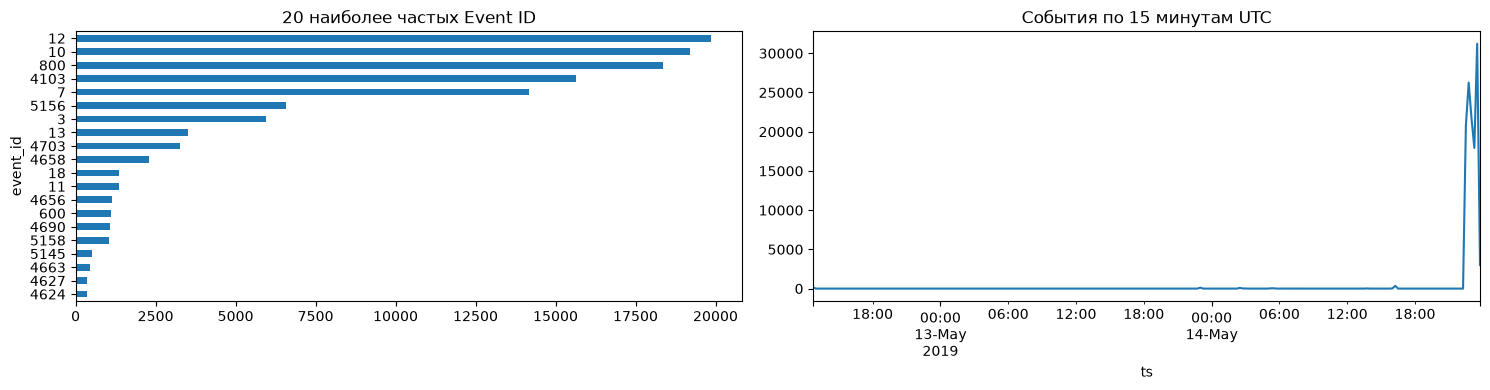

In [7]:
print("EventID распределение (топ-30):")
print(df["event_id"].value_counts().head(30).to_string())
print("\nИсходные компьютеры:")
print(df["host"].value_counts(dropna=False).to_string())
print("\nИсточники:")
print(df["source_name"].value_counts(dropna=False).head(20).to_string())
print("\nЧастые сочетания источника, Event ID и Task:")
source_event_task = (df.groupby(["source_name", "event_id", "task"], dropna=False)
                     .size().rename("events").reset_index()
                     .sort_values("events", ascending=False))
display(source_event_task.head(40))

# Count presence of structured event_data keys without retaining all nested dictionaries in memory.
field_counters = defaultdict(Counter)
source_event_totals = df["source_name"].fillna("UNKNOWN").value_counts().to_dict()
for source_name, field_names in zip(df["source_name"].fillna("UNKNOWN"), df["event_data_fields"]):
    field_counters[str(source_name)].update(field_names if isinstance(field_names, (tuple, list)) else [])
field_rows = []
for source_name, counts in field_counters.items():
    total = int(source_event_totals.get(source_name, 0))
    for field_name, count in counts.most_common(10):
        field_rows.append({"source_name": source_name, "event_data_field": field_name,
                           "events_with_field": int(count),
                           "pct_of_source_events": round(100 * count / total, 2) if total else 0.0})
print("\nКлючи event_data, наиболее часто встречающиеся внутри каждого источника:")
if field_rows:
    display(pd.DataFrame(field_rows).sort_values(["source_name", "events_with_field"], ascending=[True, False]))
else:
    print("Структурированных полей event_data не обнаружено.")
fig,ax=plt.subplots(1,2,figsize=(15,4))
df["event_id"].value_counts().head(20).sort_values().plot(kind="barh",ax=ax[0]); ax[0].set_title("20 наиболее частых Event ID")
df.set_index("ts").assign(n=1)["n"].resample("15min").sum().plot(ax=ax[1]); ax[1].set_title("События по 15 минутам UTC")
plt.tight_layout(); plt.show()

In [ ]:
print("Временной диапазон UTC:", df["ts"].min(), "-", df["ts"].max())
print("Распределение исходных компьютеров:")
display(df["host"].value_counts(dropna=False).rename_axis("host").to_frame("count"))

Временной диапазон UTC: 2019-05-12 12:58:22.531000+00:00 — 2019-05-14 23:47:44.225000+00:00
Распределение исходных компьютеров:


,count
host,
HR001.shire.com,85957
HFDC01.shire.com,28148
IT001.shire.com,6012
ACCT001.shire.com,1542


In [9]:
failed_logons=df[df["event_id"].eq(4625) & ((df["source_name"].fillna("").str.contains("Security-Auditing", case=False, regex=False)) | (df["log_name"].fillna("").str.fullmatch("Security", case=False, na=False)))]
print(f"Событий 4625 (неуспешный вход): {len(failed_logons):,}")
display(failed_logons[["ts","host","user","domain","src_ip","logon_type","message"]].head(30))

Событий 4625 (неуспешный вход): 2


,ts,host,user,domain,src_ip,logon_type,message
116818,2019-05-14 23:44:26.721000+00:00,HFDC01.shire.com,HFDC01$,SHIRE,NaN,5.0,An account failed to log on.\n\nSubject:\n\tSe...
116819,2019-05-14 23:44:26.721000+00:00,HFDC01.shire.com,HFDC01$,SHIRE,NaN,5.0,An account failed to log on.\n\nSubject:\n\tSe...


### 1.4. Создание учётных записей и изменение групп

Проверяем наличие типичных Windows Security Event ID управления учётными записями и группами. События могут отсутствовать; поэтому сначала выводим фактическое содержимое, не предполагая заранее, что нужные ID есть.

In [10]:
account_change_ids=[4720,4722,4724,4725,4726,4727,4728,4729,4730,4731,4732,4733,4734,4735,4737,4738,4740,4741,4742,4743,4754,4755,4756,4757,4758,4759,4760,4761,4762,4764,4765,4766,4781,4798,4799]
account_changes=df[df["event_id"].isin(account_change_ids) & ((df["source_name"].fillna("").str.contains("Security-Auditing", case=False, regex=False)) | (df["log_name"].fillna("").str.fullmatch("Security", case=False, na=False)))].copy()
print("События управления учётными записями/группами:",len(account_changes))
if len(account_changes): display(account_changes[["ts","host","event_id","subject_user","target_user","message"]].head(100))
else: print("Выбранные Event ID отсутствуют; это допустимо для данного набора журналов.")

События управления учётными записями/группами: 6


,ts,host,event_id,subject_user,target_user,message
21227,2019-05-14 22:44:11.968000+00:00,HR001.shire.com,4799,nmartha,Administrators,A security-enabled local group membership was ...
42995,2019-05-14 22:56:00.293000+00:00,HR001.shire.com,4735,HR001$,Administrators,A security-enabled local group was changed.\n\...
83521,2019-05-14 23:26:06.621000+00:00,IT001.shire.com,4735,IT001$,Administrators,A security-enabled local group was changed.\n\...
106491,2019-05-14 23:43:11.064000+00:00,HFDC01.shire.com,4799,HFDC01$,Administrators,A security-enabled local group membership was ...
116964,2019-05-14 23:44:28.691000+00:00,HFDC01.shire.com,4799,HFDC01$,Administrators,A security-enabled local group membership was ...
116986,2019-05-14 23:44:28.871000+00:00,HFDC01.shire.com,4799,HFDC01$,Backup Operators,A security-enabled local group membership was ...


In [11]:
display(df[df["event_id"].isin(account_change_ids)].groupby(["event_id","task"],dropna=False).size().rename("count").reset_index().sort_values("count",ascending=False))

,event_id,task,count
1,4799,Security Group Management,4
0,4735,Security Group Management,2


### 1.5. Поиск индикаторов по нескольким источникам телеметрии

Распределение Event ID и источников помогает понять состав журналов, но само по себе не выявляет атаку. Ниже выполняется предварительный поиск по PowerShell, созданию/доступу к процессам, сетевым событиям и ключам автозапуска. Совпадения являются эвристическими кандидатами: допустимы ложные срабатывания, а отсутствие совпадений не исключает атаку.


Проверяются не только Security Auditing, но и PowerShell Script Block/Module Logging, Sysmon, Windows Filtering Platform, WMI-Activity и события Service Control Manager. Совпадения по текстовым правилам — приоритетные кандидаты для ручной проверки, не готовый вердикт об атаке.


In [12]:
# Источники PowerShell и их типы событий: это отдельная телеметрия, не ограниченная Security Auditing.
ps_mask = df["source_name"].fillna("").str.contains("powershell", case=False, regex=False) | df["log_name"].fillna("").str.contains("powershell", case=False, regex=False)
ps_df = df[ps_mask].copy()
print(f"Событий из PowerShell-источников: {len(ps_df):,}")
if len(ps_df):
    display(ps_df.groupby(["source_name", "event_id", "task"], dropna=False).size().rename("count").reset_index().sort_values("count", ascending=False).head(30))

# Сбор только нужных event ID уменьшает расход памяти на строковый поиск.
hunt_ids = {1, 3, 7, 10, 11, 12, 13, 14, 4103, 4104, 4105, 4106, 800, 4688, 4697, 7045, 5156, 5157, 5158, 53504}
hunt_df = df[df.event_id.isin(hunt_ids)].copy()
hunt_fields = ["message", "command_line", "image", "parent_image", "target_image", "target_object", "details", "script_block_text", "service_name", "service_path", "application", "destination_host", "task"]
# Составной текст создаётся только для выбранных потенциально информативных событий.
hunt_df["_hunt_text"] = hunt_df[hunt_fields].fillna("").astype(str).agg(" | ".join, axis=1)

hunt_patterns = {
    "PowerShell: кодированная команда / загрузка / выполнение": r"(?i)(?:-enc(?:odedcommand)?\b|frombase64string|downloadstring|invoke-expression|\biex\b|net\.webclient|start-bitstransfer|invoke-webrequest|executionpolicy\s+bypass|windowstyle\s+hidden)",
    "Скриптовые хосты / LOLBin": r"(?i)(?:wscript\.exe|cscript\.exe|mshta\.exe|regsvr32\.exe|rundll32\.exe|certutil\.exe|bitsadmin\.exe)",
    "Доступ к учётным данным / LSASS": r"(?i)(?:mimikatz|sekurlsa|comsvcs\.dll|procdump|MiniDump)",
    "Закрепление / служба / автозапуск": r"(?i)(?:\\currentversion\\run(?:once)?\\|\\services\\|\\winlogon\\(?:shell|userinit|notify)|image file execution options|appinit_dlls|adobe flash updater|\.vbs\b|sc\.exe\s+create|new service named|service was installed)",
    "Разведка / удалённое выполнение": r"(?i)(?:nltest\.exe|psexec|wmic\.exe|invoke-command|enter-pssession|schtasks\.exe|net\.exe\s+(?:user|group|localgroup|view|use)|whoami(?:\.exe)?|admin\$|c\$)",
}
for category, pattern in hunt_patterns.items():
    if category == "Доступ к учётным данным / LSASS":
        # Exact target-process context for Sysmon ProcessAccess; do not flag every ordinary mention of lsass.exe.
        explicit_dump_tool = hunt_df["_hunt_text"].str.contains(pattern, regex=True, na=False)
        sysmon_hunt_mask = (
            hunt_df["source_name"].fillna("").str.contains("Sysmon", case=False, regex=False)
            | hunt_df["log_name"].fillna("").str.contains("Sysmon", case=False, regex=False)
        )
        lsass_target = sysmon_hunt_mask & hunt_df["event_id"].eq(10) & (
            hunt_df["target_image"].fillna("").str.contains(r"lsass\.exe$", case=False, regex=True)
            | hunt_df["message"].fillna("").str.contains(r"TargetImage:\s*.*lsass\.exe", case=False, regex=True)
        )
        hunt_df[category] = explicit_dump_tool | lsass_target
    else:
        hunt_df[category] = hunt_df["_hunt_text"].str.contains(pattern, regex=True, na=False)

category_counts = pd.DataFrame([
    {"category": category, "matching_events": int(hunt_df[category].sum())}
    for category in hunt_patterns
]).sort_values("matching_events", ascending=False)
display(category_counts)

hit_columns = ["ts", "host", "source_name", "event_id", "task", "user", "image", "parent_image", "command_line", "target_image", "target_object", "service_name", "service_path", "script_block_text"]
any_hit = hunt_df[list(hunt_patterns)].any(axis=1)
hunt_hits = hunt_df.loc[any_hit].copy()
hunt_hits["matched_categories"] = hunt_hits.apply(lambda row: "; ".join(cat for cat in hunt_patterns if bool(row[cat])), axis=1)
# Explainable triage ordering, not an incident severity score: credential/persistence indicators rank first.
rule_weights = {
    "PowerShell: кодированная команда / загрузка / выполнение": 3,
    "Скриптовые хосты / LOLBin": 2,
    "Доступ к учётным данным / LSASS": 5,
    "Закрепление / служба / автозапуск": 5,
    "Разведка / удалённое выполнение": 2,
}
hunt_hits["review_priority"] = hunt_hits.apply(lambda row: sum(weight for category, weight in rule_weights.items() if bool(row[category])), axis=1)
hunt_hits = hunt_hits.sort_values(["review_priority", "ts"], ascending=[False, True])
print(f"Событий-кандидатов по строковым индикаторам: {len(hunt_hits):,}")
if len(hunt_hits):
    display(hunt_hits[hit_columns + ["matched_categories", "review_priority"]].head(60))
else:
    print("По этим строковым индикаторам совпадений нет; это не доказывает отсутствия атаки.")

# Другие источники телеметрии также анализируются отдельно, а не смешиваются с Windows Security.
wmi_mask = df["source_name"].fillna("").str.contains("WMI-Activity", case=False, regex=False) | df["log_name"].fillna("").str.contains("WMI-Activity", case=False, regex=False)
wmi_events = df[wmi_mask].copy()
print(f"Событий WMI-Activity: {len(wmi_events):,}")
if len(wmi_events):
    display(wmi_events[["ts", "host", "event_id", "task", "user", "message"]].head(30))

wfp_source_mask = (
    df["source_name"].fillna("").str.contains("Security-Auditing|Filtering Platform|Firewall", case=False, regex=True)
    | df["log_name"].fillna("").str.contains("Security|Filtering Platform|Firewall", case=False, regex=True)
)
firewall_events = df[df.event_id.isin([5156, 5157, 5158]) & wfp_source_mask].copy()
print("События Windows Filtering Platform из соответствующих источников (5156/5157/5158):", len(firewall_events))
if len(firewall_events):
    display(firewall_events.groupby(["source_name", "event_id", "task"], dropna=False).size().rename("count").reset_index().sort_values("count", ascending=False).head(30))
    display(firewall_events[["ts", "host", "event_id", "user", "src_ip", "src_port", "dst_ip", "dst_port", "application", "message"]].head(40))

security_source_mask = (
    df["source_name"].fillna("").str.contains("Security-Auditing", case=False, regex=False)
    | df["log_name"].fillna("").str.fullmatch("Security", case=False, na=False)
)
scm_source_mask = (
    df["source_name"].fillna("").str.contains("Service Control Manager", case=False, regex=False)
    | df["log_name"].fillna("").str.fullmatch("System", case=False, na=False)
)
service_events = df[(df.event_id.eq(4697) & security_source_mask)
                    | (df.event_id.eq(7045) & scm_source_mask)
                    | df["source_name"].fillna("").str.contains("Service Control Manager", case=False, regex=False)].copy()
print(f"Событий установки/управления службами из Security/SCM (4697/7045): {len(service_events):,}")
if len(service_events):
    display(service_events[["ts", "host", "source_name", "event_id", "service_name", "service_path", "user", "message"]].head(40))

# Отдельная проверка Sysmon Event ID 10 — какие процессы обращались к LSASS.
sysmon_mask = (
    df["source_name"].fillna("").str.contains("Sysmon", case=False, regex=False)
    | df["log_name"].fillna("").str.contains("Sysmon", case=False, regex=False)
)
process_access = df[sysmon_mask & df.event_id.eq(10)].copy()
if len(process_access):
    lsass_mask = process_access["target_image"].fillna("").str.contains(r"lsass\.exe$", case=False, regex=True) | process_access["message"].fillna("").str.contains(r"TargetImage:\s*.*lsass\.exe", case=False, regex=True)
    lsass_access = process_access[lsass_mask]
    print(f"Sysmon Event ID 10 (Process Access): {len(process_access):,}; target=LSASS: {len(lsass_access):,}")
    if len(lsass_access): display(lsass_access[["ts", "host", "user", "image", "target_image", "message"]].head(30))

# Для Sysmon Event ID 3 — обзор сетевых соединений по доступным структурированным полям.
network_events = df[sysmon_mask & df.event_id.eq(3)].copy()
print(f"Sysmon Event ID 3 (Network Connection): {len(network_events):,}")
network_cols = [c for c in ["host", "image", "src_ip", "dst_ip", "dst_port"] if c in network_events.columns]
if len(network_events) and all(c in network_events.columns for c in ["src_ip", "dst_ip"]):
    display(network_events.groupby(network_cols, dropna=False).size().rename("events").reset_index().sort_values("events", ascending=False).head(25))

# Сетевые правила Windows Filtering Platform (отдельный источник от Sysmon).
if len(firewall_events):
    firewall_cols = [c for c in ["source_name", "event_id", "host", "application", "src_ip", "src_port", "dst_ip", "dst_port"] if c in firewall_events.columns]
    display(firewall_events.groupby(firewall_cols, dropna=False).size().rename("events").reset_index().sort_values("events", ascending=False).head(30))


Событий из PowerShell-источников: 36,055


,source_name,event_id,task,count
11,PowerShell,800,Pipeline Execution Details,18366
1,Microsoft-Windows-PowerShell,4103,Executing Pipeline,15632
10,PowerShell,600,Provider Lifecycle,1106
3,Microsoft-Windows-PowerShell,4105,Starting Command,297
4,Microsoft-Windows-PowerShell,4106,Stopping Command,289
8,PowerShell,400,Engine Lifecycle,183
2,Microsoft-Windows-PowerShell,4104,Execute a Remote Command,140
7,Microsoft-Windows-PowerShell,53504,PowerShell Named Pipe IPC,14
6,Microsoft-Windows-PowerShell,40962,PowerShell Console Startup,12
5,Microsoft-Windows-PowerShell,40961,PowerShell Console Startup,12


,category,matching_events
0,PowerShell: кодированная команда / загрузка / ...,33990
3,Закрепление / служба / автозапуск,1013
4,Разведка / удалённое выполнение,330
1,Скриптовые хосты / LOLBin,319
2,Доступ к учётным данным / LSASS,117


Событий-кандидатов по строковым индикаторам: 35,570


,ts,host,source_name,event_id,task,user,image,parent_image,command_line,target_image,target_object,service_name,service_path,script_block_text,matched_categories,review_priority
8316,2019-05-14 22:32:23.415000+00:00,HR001.shire.com,Microsoft-Windows-Sysmon,1,Process Create (rule: ProcessCreate),SHIRE\nmartha,C:\Windows\System32\WindowsPowerShell\v1.0\pow...,C:\Windows\System32\wscript.exe,"""C:\Windows\System32\WindowsPowerShell\v1.0\po...",NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
47020,2019-05-14 22:59:49.632000+00:00,HR001.shire.com,Microsoft-Windows-Sysmon,1,Process Create (rule: ProcessCreate),SHIRE\pgustavo,C:\Windows\System32\WindowsPowerShell\v1.0\pow...,C:\Windows\System32\wscript.exe,"""C:\Windows\System32\WindowsPowerShell\v1.0\po...",NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
49538,2019-05-14 23:01:56.068000+00:00,HR001.shire.com,PowerShell,800,Pipeline Execution Details,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
49539,2019-05-14 23:01:56.068000+00:00,HR001.shire.com,PowerShell,800,Pipeline Execution Details,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
49540,2019-05-14 23:01:56.083000+00:00,HR001.shire.com,Microsoft-Windows-PowerShell,4103,Executing Pipeline,pgustavo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
49541,2019-05-14 23:01:56.083000+00:00,HR001.shire.com,Microsoft-Windows-PowerShell,4103,Executing Pipeline,pgustavo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
63373,2019-05-14 23:11:17.980000+00:00,HR001.shire.com,PowerShell,800,Pipeline Execution Details,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
63384,2019-05-14 23:11:17.995000+00:00,HR001.shire.com,PowerShell,800,Pipeline Execution Details,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
63386,2019-05-14 23:11:18+00:00,HR001.shire.com,Microsoft-Windows-PowerShell,4103,Executing Pipeline,pgustavo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
63387,2019-05-14 23:11:18+00:00,HR001.shire.com,Microsoft-Windows-PowerShell,4103,Executing Pipeline,pgustavo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10


...

Sysmon Event ID 10 (Process Access): 19,199; target=LSASS: 117


,ts,host,user,image,target_image,message
925,2019-05-14 22:31:26.910000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
975,2019-05-14 22:31:26.940000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
1643,2019-05-14 22:31:32.684000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
1644,2019-05-14 22:31:32.685000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
1796,2019-05-14 22:31:34.064000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
1801,2019-05-14 22:31:34.065000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
1948,2019-05-14 22:31:34.868000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
1949,2019-05-14 22:31:34.868000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
2285,2019-05-14 22:31:36.925000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...
2286,2019-05-14 22:31:36.925000+00:00,HR001.shire.com,SYSTEM,C:\Windows\system32\svchost.exe,C:\Windows\system32\lsass.exe,Process accessed:\nRuleName: \nUtcTime: 2019-0...


Sysmon Event ID 3 (Network Connection): 5,951


,host,image,src_ip,dst_ip,dst_port,events
973,HR001.shire.com,C:\Windows\System32\WindowsPowerShell\v1.0\pow...,172.18.39.106,10.0.10.106,443,2743
776,HFDC01.shire.com,C:\Windows\System32\svchost.exe,172.18.39.5,172.18.39.102,5985,383
32,HFDC01.shire.com,C:\Windows\System32\WindowsPowerShell\v1.0\pow...,172.18.39.5,10.0.10.106,443,378
1023,IT001.shire.com,C:\Windows\System32\svchost.exe,172.18.39.105,172.18.39.102,5985,355
992,HR001.shire.com,C:\Windows\System32\svchost.exe,172.18.39.106,172.18.39.102,5985,260
986,HR001.shire.com,C:\Windows\System32\lsass.exe,172.18.39.106,172.18.39.5,88,149
1,ACCT001.shire.com,C:\Windows\System32\svchost.exe,172.18.39.100,172.18.39.102,5985,124
31,HFDC01.shire.com,C:\Windows\ADWS\Microsoft.ActiveDirectory.WebS...,0:0:0:0:0:0:0:1,0:0:0:0:0:0:0:1,389,77
822,HFDC01.shire.com,C:\Windows\System32\svchost.exe,fe80:0:0:0:e086:822b:9735:45c8,fe80:0:0:0:e086:822b:9735:45c8,389,47
34,HFDC01.shire.com,C:\Windows\System32\dfsrs.exe,fe80:0:0:0:e086:822b:9735:45c8,fe80:0:0:0:e086:822b:9735:45c8,389,30


,source_name,event_id,host,application,src_ip,src_port,dst_ip,dst_port,events
6753,Microsoft-Windows-Security-Auditing,5158,HFDC01.shire.com,\device\harddiskvolume2\windows\system32\lsass...,::,54172,NaN,NaN,52
6667,Microsoft-Windows-Security-Auditing,5158,HFDC01.shire.com,\device\harddiskvolume2\windows\system32\lsass...,0.0.0.0,54172,NaN,NaN,27
1120,Microsoft-Windows-Security-Auditing,5156,HFDC01.shire.com,\device\harddiskvolume2\windows\system32\lsass...,::1,54172,::1,53,18
6853,Microsoft-Windows-Security-Auditing,5158,HFDC01.shire.com,\device\harddiskvolume2\windows\system32\svcho...,::,54172,NaN,NaN,16
213,Microsoft-Windows-Security-Auditing,5156,HFDC01.shire.com,System,172.18.39.5,138,172.18.255.255,138,12
1046,Microsoft-Windows-Security-Auditing,5156,HFDC01.shire.com,\device\harddiskvolume2\windows\system32\lsass...,172.18.39.5,54172,172.18.39.5,53,12
5930,Microsoft-Windows-Security-Auditing,5156,IT001.shire.com,System,172.18.39.105,138,172.18.255.255,138,10
738,Microsoft-Windows-Security-Auditing,5156,HFDC01.shire.com,\device\harddiskvolume2\windows\system32\dns.exe,::1,54172,::1,53,8
2284,Microsoft-Windows-Security-Auditing,5156,HR001.shire.com,System,172.18.39.106,138,172.18.255.255,138,8
1799,Microsoft-Windows-Security-Auditing,5156,HFDC01.shire.com,\device\harddiskvolume2\windows\system32\svcho...,::1,54172,::1,53,7


## 2. Разбиение потока событий на локальные сеансы

Используем доступные `LogonId`, `TargetLogonId` или `SubjectLogonId` из `event_data`. Ключ обязательно включает исходный компьютер: одинаковый LogonId на разных хостах не гарантирует один сеанс.

In [13]:
def make_session_key(row):
    lid=row["logon_id"]; host=row["host"]
    if pd.isna(lid) or not lid or str(lid).lower() in {"0x0","0","-"} or pd.isna(host): return None
    return (str(host),str(lid).lower())
df["session_key"]=df.apply(make_session_key,axis=1)
print(f"Событий с LogonId: {df.session_key.notna().sum():,}; уникальных локальных ключей: {df.session_key.nunique():,}")
display(df[["ts","host","event_id","user","logon_id","session_key"]].head(10))
coverage = df.groupby("source_name", dropna=False).agg(
    events=("event_id", "size"),
    events_with_logon_id=("session_key", lambda values: int(values.notna().sum())),
).sort_values("events", ascending=False)
coverage["with_logon_id_pct"] = (100 * coverage["events_with_logon_id"] / coverage["events"]).round(2)
print("Покрытие группировки LogonId по источникам (остальные события остаются в разведке и поиске индикаторов):")
display(coverage)


Событий с LogonId: 11,661; уникальных локальных ключей: 363


,ts,host,event_id,user,logon_id,session_key
0,2019-05-12 12:58:22.531000+00:00,HFDC01.shire.com,53504,pgustavo,NaN,None
1,2019-05-12 12:58:33.917000+00:00,HFDC01.shire.com,4104,pgustavo,NaN,None
2,2019-05-12 12:58:33.917000+00:00,HFDC01.shire.com,4105,pgustavo,NaN,None
3,2019-05-12 12:58:40.536000+00:00,HFDC01.shire.com,4104,pgustavo,NaN,None
4,2019-05-12 12:58:40.536000+00:00,HFDC01.shire.com,4105,pgustavo,NaN,None
5,2019-05-12 12:58:40.566000+00:00,HFDC01.shire.com,4104,pgustavo,NaN,None
6,2019-05-12 12:58:40.566000+00:00,HFDC01.shire.com,4105,pgustavo,NaN,None
7,2019-05-12 12:58:40.569000+00:00,HFDC01.shire.com,4104,pgustavo,NaN,None
8,2019-05-12 12:58:40.569000+00:00,HFDC01.shire.com,4105,pgustavo,NaN,None
9,2019-05-12 12:58:40.570000+00:00,HFDC01.shire.com,4106,pgustavo,NaN,None


Покрытие группировки LogonId по источникам (остальные события остаются в разведке и поиске индикаторов):


,events,events_with_logon_id,with_logon_id_pct
source_name,,,
Microsoft-Windows-Sysmon,66349,308,0.46
PowerShell,19656,0,0.00
Microsoft-Windows-Security-Auditing,19092,11353,59.46
Microsoft-Windows-PowerShell,16399,0,0.00
Microsoft-Windows-WMI-Activity,53,0,0.00
Microsoft-Windows-Directory-Services-SAM,49,0,0.00
Service Control Manager,32,0,0.00
Microsoft-Windows-Windows Firewall With Advanced Security,16,0,0.00
Microsoft-Windows-GroupPolicy,5,0,0.00


In [14]:
def first_nonempty(s, default=None):
    if s is None:
        return default
    s = s.dropna()
    if s.empty:
        return default
    invalid = {"", "-", "none", "null", "(null)", "nan", "unknown"}
    valid = ~s.astype(str).str.strip().str.casefold().isin(invalid)
    s = s[valid]
    return s.iloc[0] if not s.empty else default

def build_sessions(events):
    result=[]
    for key,g in events.dropna(subset=["session_key","ts"]).groupby("session_key",sort=False):
        g=g.sort_values("ts"); logons=g[g.event_id.eq(4624)]
        session_user = first_nonempty(logons.target_user, first_nonempty(g.target_user, first_nonempty(g.subject_user, first_nonempty(g.user, "UNKNOWN"))))
        session_domain = first_nonempty(logons.domain, first_nonempty(g.domain))
        result.append({"session_key":key,"host":key[0],"logon_id":key[1],
          "user":str(session_user),
          "user_key":canonical_account_key(session_user, session_domain),
          "domain":session_domain,
          "logon_type":first_nonempty(logons.logon_type,first_nonempty(g.logon_type)),
          # In a session summary, src_ip must be the client address from a successful logon (4624).
          # Sysmon Event ID 3 uses SourceIp for the connection endpoint, often the local host; do not
          # substitute it into a login record when no successful-logon event exists.
          "src_ip":first_nonempty(logons.src_ip),
          "logon_guid":first_nonempty(logons.logon_guid,first_nonempty(g.logon_guid)),
          "ts_start":g.ts.min(),"ts_end":g.ts.max(),"duration_s":(g.ts.max()-g.ts.min()).total_seconds(),
          "n_events":len(g),"event_seq":[int(x) for x in g.event_id.dropna()],
          "process_seq":[Path(str(x).replace("\\","/")).name.lower() for x in g.image.dropna()]})
    return pd.DataFrame(result)
sess_df=build_sessions(df)
if len(sess_df): sess_df=sess_df.sort_values("ts_start").reset_index(drop=True)
print(f"Локальных сеансов: {len(sess_df):,}")
display(sess_df.head(10))

Локальных сеансов: 363


,session_key,host,logon_id,user,user_key,domain,logon_type,src_ip,logon_guid,ts_start,ts_end,duration_s,n_events,event_seq,process_seq
0,"(HR001.shire.com, 0x3e4)",HR001.shire.com,0x3e4,HR001$,hr001$,SHIRE,NaN,NaN,{03ba39f5-ea63-5ccb-0000-0020e4030000},2019-05-14 22:31:15.219000+00:00,2019-05-14 23:47:38.019000+00:00,4582.800,1179,"[4690, 4658, 4656, 4663, 4658, 4658, 4658, 466...","[svchost.exe, svchost.exe, svchost.exe, svchos..."
1,"(HFDC01.shire.com, 0x3e7)",HFDC01.shire.com,0x3e7,SYSTEM,nt authority\system,NT AUTHORITY,5.0,NaN,{00000000-0000-0000-0000-000000000000},2019-05-14 22:31:16.916000+00:00,2019-05-14 23:47:38.035000+00:00,4581.119,3578,"[4703, 4703, 4703, 4703, 4703, 4703, 4703, 470...","[svchost.exe, svchost.exe, svchost.exe, svchos..."
2,"(HFDC01.shire.com, 0x10d80673)",HFDC01.shire.com,0x10d80673,HFDC01$,hfdc01$,SHIRE.COM,3.0,::1,{5926A193-E2CE-CB62-863B-45F094C0DDEC},2019-05-14 22:31:21.822000+00:00,2019-05-14 22:31:21.823000+00:00,0.001,4,"[4672, 4624, 4627, 4634]",[]
3,"(HR001.shire.com, 0x3e7)",HR001.shire.com,0x3e7,SYSTEM,nt authority\system,NT AUTHORITY,5.0,NaN,{00000000-0000-0000-0000-000000000000},2019-05-14 22:31:26.793000+00:00,2019-05-14 23:47:41.686000+00:00,4574.893,1262,"[4663, 4658, 4611, 4658, 4690, 4656, 4673, 462...","[winlogon.exe, winlogon.exe, winlogon.exe, win..."
4,"(HR001.shire.com, 0x844ebc)",HR001.shire.com,0x844ebc,nmartha,nmartha,SHIRE,11.0,127.0.0.1,{00000000-0000-0000-0000-000000000000},2019-05-14 22:31:26.896000+00:00,2019-05-14 22:31:27.076000+00:00,0.180,3,"[4624, 4672, 4634]",[svchost.exe]
5,"(HR001.shire.com, 0x844ee0)",HR001.shire.com,0x844ee0,nmartha,nmartha,SHIRE,11.0,127.0.0.1,{00000000-0000-0000-0000-000000000000},2019-05-14 22:31:26.896000+00:00,2019-05-14 22:31:27.076000+00:00,0.180,2,"[4624, 4634]",[svchost.exe]
6,"(HR001.shire.com, 0xc0cc4)",HR001.shire.com,0xc0cc4,nmartha,nmartha,SHIRE,9.0,NaN,{03ba39f5-e67a-5cda-0000-0020c40c0c00},2019-05-14 22:31:26.911000+00:00,2019-05-14 23:44:19.273000+00:00,4372.362,2243,"[4801, 1, 4673, 1, 4673, 1, 4689, 4658, 4658, ...","[taskhostw.exe, svchost.exe, backgroundtaskhos..."
7,"(HR001.shire.com, 0x844f46)",HR001.shire.com,0x844f46,nmartha,nmartha,SHIRE,7.0,NaN,{b4a86f73-c773-9669-67f5-68c6571eea31},2019-05-14 22:31:27.010000+00:00,2019-05-14 22:31:27.077000+00:00,0.067,3,"[4672, 4624, 4634]",[lsass.exe]
8,"(HR001.shire.com, 0x84501a)",HR001.shire.com,0x84501a,nmartha,nmartha,SHIRE,7.0,NaN,{00000000-0000-0000-0000-000000000000},2019-05-14 22:31:27.010000+00:00,2019-05-14 22:31:27.076000+00:00,0.066,2,"[4624, 4634]",[lsass.exe]
9,"(HFDC01.shire.com, 0x10d807a4)",HFDC01.shire.com,0x10d807a4,HFDC01$,hfdc01$,SHIRE.COM,3.0,fe80::e086:822b:9735:45c8,{C7890301-EA6C-8477-B27B-1E4BFFA4CD6E},2019-05-14 22:31:30.932000+00:00,2019-05-14 22:31:41.664000+00:00,10.732,6,"[4672, 4624, 4627, 5140, 5145, 4634]",[]


In [15]:
# Пример: показать первый сформированный сеанс, если он есть.
if len(sess_df):
    example_key=sess_df.iloc[0]["session_key"]
    display(df[df["session_key"].map(lambda value: value == example_key)][["ts","host","event_id","user","logon_id","task"]].head(50))
else: print("Нет сеансов с доступным LogonId.")

,ts,host,event_id,user,logon_id,task
834,2019-05-14 22:31:15.219000+00:00,HR001.shire.com,4690,HR001$,0x3e4,Handle Manipulation
835,2019-05-14 22:31:15.219000+00:00,HR001.shire.com,4658,HR001$,0x3e4,Registry
836,2019-05-14 22:31:15.219000+00:00,HR001.shire.com,4656,HR001$,0x3e4,Registry
837,2019-05-14 22:31:15.219000+00:00,HR001.shire.com,4663,HR001$,0x3e4,Registry
838,2019-05-14 22:31:15.219000+00:00,HR001.shire.com,4658,HR001$,0x3e4,Registry
2016,2019-05-14 22:31:35.249000+00:00,HR001.shire.com,4690,HR001$,0x3e4,Handle Manipulation
2017,2019-05-14 22:31:35.249000+00:00,HR001.shire.com,4656,HR001$,0x3e4,Registry
2018,2019-05-14 22:31:35.249000+00:00,HR001.shire.com,4658,HR001$,0x3e4,Registry
2019,2019-05-14 22:31:35.249000+00:00,HR001.shire.com,4663,HR001$,0x3e4,Registry
2020,2019-05-14 22:31:35.249000+00:00,HR001.shire.com,4658,HR001$,0x3e4,Registry


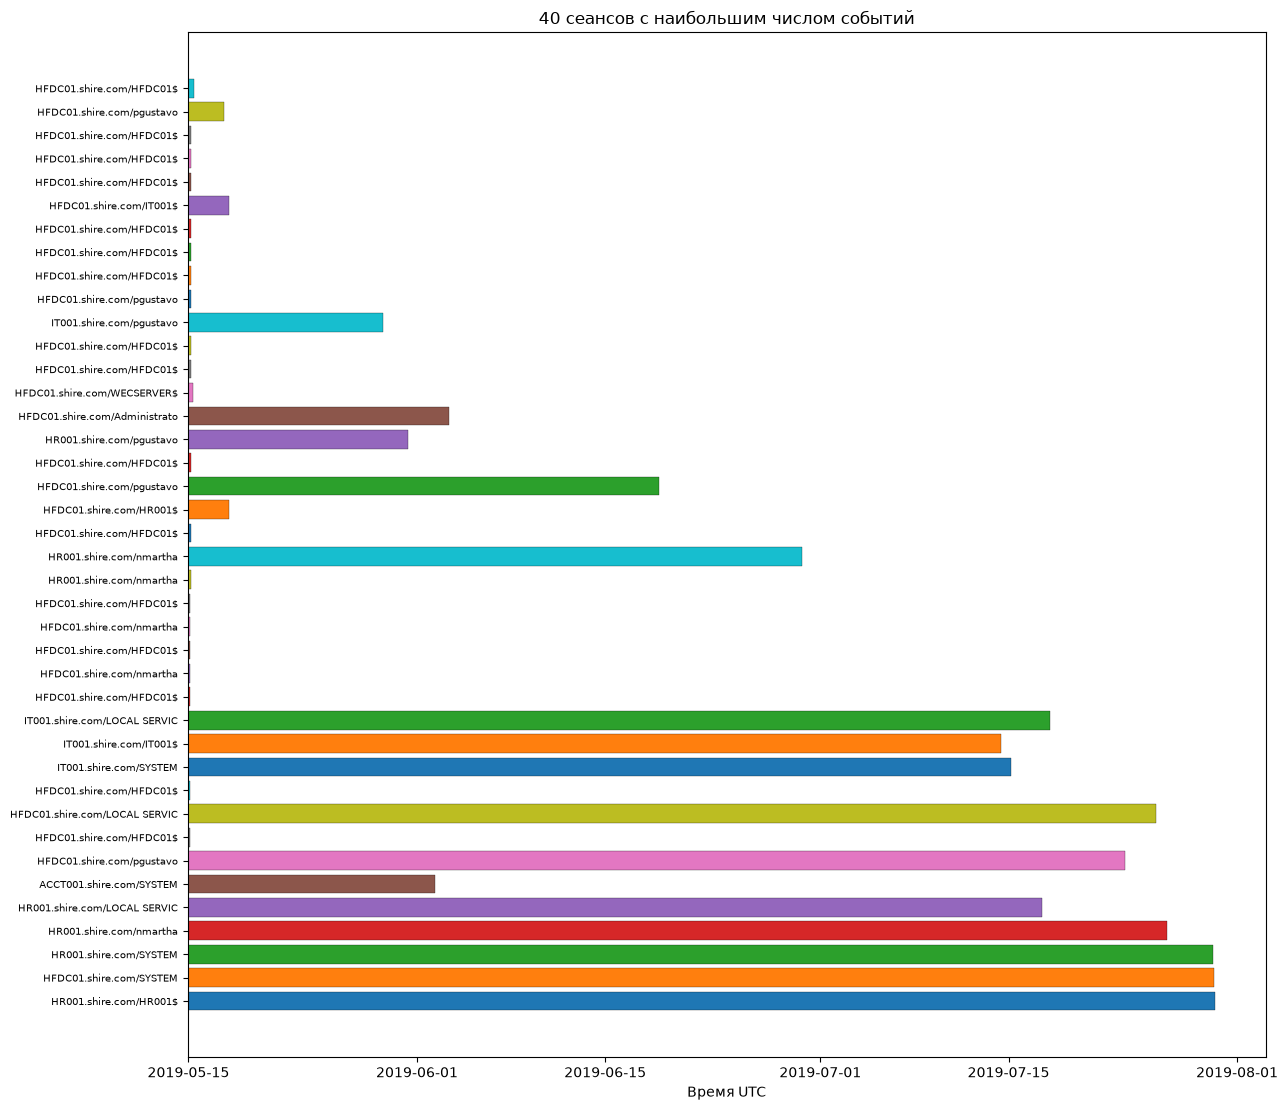

In [16]:
plot_sessions = sess_df.nlargest(40, "n_events").sort_values("ts_start") if "n_events" in sess_df.columns else pd.DataFrame()
if len(plot_sessions):
    fig,ax=plt.subplots(figsize=(13,max(4,.28*len(plot_sessions))))
    for y,r in enumerate(plot_sessions.itertuples()): ax.barh(y,max(r.duration_s/60,.2),left=r.ts_start,edgecolor="black",linewidth=.2)
    ax.set_yticks(range(len(plot_sessions))); ax.set_yticklabels([f"{r.host}/{str(r.user)[:12]}" for r in plot_sessions.itertuples()],fontsize=7)
    ax.set_xlabel("Время UTC"); ax.set_title("40 сеансов с наибольшим числом событий"); plt.tight_layout(); plt.show()
else:
    print("Нет локальных сеансов для временной диаграммы: LogonId в выбранных событиях отсутствует.")

## 3. Префиксное дерево для поиска необычных цепочек событий

Редкие последовательности могут быть интересны для проверки, но необычность сама по себе не доказывает вредоносность.

Для снижения смещения по типу входа короткая базовая выборка формируется отдельно по каждому `LogonType`, а затем объединяется в общую модель. Необычность — относительная оценка последовательности, не доказательство атаки.

Оценка проводится на отложенных базовых и более длинных сеансах, не использованных в обучении; короткие последовательности менее 5 событий не входят в основное ранжирование, если доступны более длинные. Поэтому итоговый рейтинг следует интерпретировать как относительный приоритет проверки, а не как вероятность атаки.


### 3.1. Классическое префиксное дерево на строках (демонстрация)

Прежде чем строить префиксное дерево над последовательностями событий, посмотрим на каноническую конструкцию: префиксное дерево (в англоязычной литературе часто называется trie) над набором *строк*. Каждое слово — это путь от корня по символам; общие префиксы разных слов *склеиваются* в одну ветвь, поэтому дерево компактно представляет всё множество.

Реализуем trie на базе готовой библиотеки графов **`networkx.DiGraph`**: каждый узел — это кортеж символов префикса (`()` — корень, `('c',)`, `('c','a')`, `('c','a','r')` …), каждое ребро — добавление одного символа. Узел хранит атрибут `count` — сколько раз этот префикс встретился среди вставленных слов; листовой узел дополнительно помечен флагом `terminal`.


In [17]:
def build_string_trie(words):
    G=nx.DiGraph(); G.add_node((),count=0,terminal=False)
    for word in words:
        prefix=(); G.nodes[prefix]["count"]+=1
        for ch in word:
            child=prefix+(ch,)
            if child not in G: G.add_node(child,count=0,terminal=False)
            G.add_edge(prefix,child,label=ch); G.nodes[child]["count"]+=1; prefix=child
        G.nodes[prefix]["terminal"]=True
    return G
words=["car","card","care","cat","do","dog","dome","domino"]
trie_demo=build_string_trie(words)
print(f"Демонстрационное дерево: {trie_demo.number_of_nodes()} узлов, {trie_demo.number_of_edges()} рёбер")

Демонстрационное дерево: 15 узлов, 14 рёбер


In [18]:
display(pd.DataFrame([{"prefix":"".join(n),"count":d["count"],"terminal":d["terminal"]} for n,d in trie_demo.nodes(data=True)]).sort_values("count",ascending=False))

,prefix,count,terminal
0,,8,False
1,c,4,False
2,ca,4,False
8,do,4,True
7,d,4,False
3,car,3,True
10,dom,2,False
6,cat,1,True
5,care,1,True
4,card,1,True


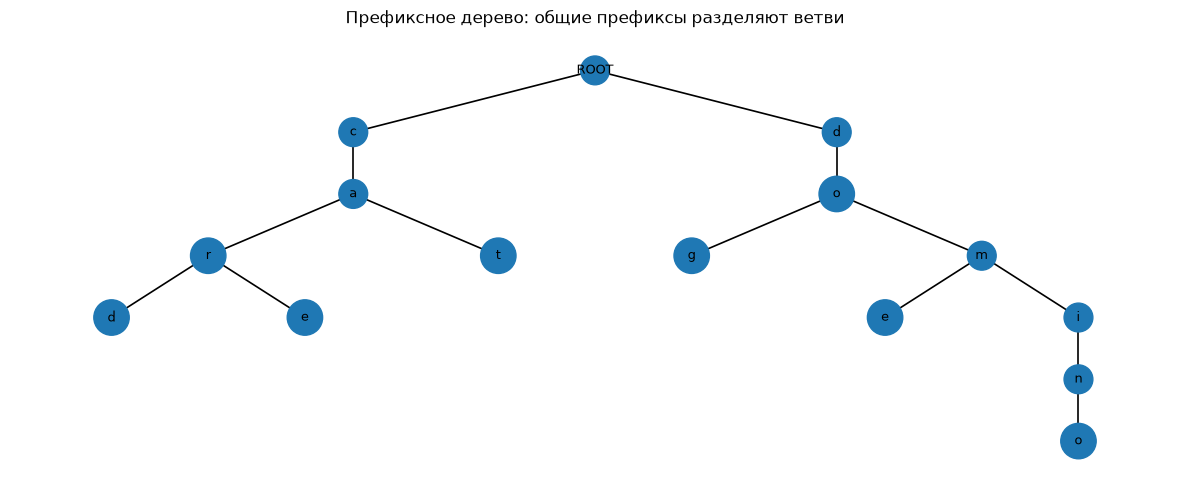

In [19]:
# Для trie используем иерархическую раскладку: родитель всегда выше потомков.
def tree_positions(tree, root=()):
    children_map = {node: list(tree.successors(node)) for node in tree.nodes()}
    x_positions = {}
    next_x = [0]

    def visit(node, depth):
        children = children_map.get(node, [])
        if not children:
            x_positions[node] = (next_x[0], -depth)
            next_x[0] += 1
        else:
            child_x = []
            for child in children:
                visit(child, depth + 1)
                child_x.append(x_positions[child][0])
            x_positions[node] = (sum(child_x) / len(child_x), -depth)

    visit(root, 0)
    if x_positions:
        min_x = min(x for x, _ in x_positions.values())
        max_x = max(x for x, _ in x_positions.values())
        span = max(max_x - min_x, 1)
        return {node: ((x - min_x) / span, y) for node, (x, y) in x_positions.items()}
    return {}

pos_demo = tree_positions(trie_demo)
labels_demo = {n: ("ROOT" if n == () else "".join(n)[-1]) for n in trie_demo.nodes()}
plt.figure(figsize=(12, 5))
nx.draw_networkx_edges(trie_demo, pos_demo, arrows=False, width=1.2)
nx.draw_networkx_nodes(
    trie_demo, pos_demo,
    node_size=[650 if trie_demo.nodes[n]["terminal"] else 430 for n in trie_demo.nodes()]
)
nx.draw_networkx_labels(trie_demo, pos_demo, labels_demo, font_size=9)
plt.title("Префиксное дерево: общие префиксы разделяют ветви")
plt.axis("off")
plt.tight_layout()
plt.show()

In [20]:
def hierarchy_pos(G, root=(), width=1.0, vert_gap=0.3, xcenter=0.0):
    """Иерархическая раскладка из исходного шаблона, адаптированная к trie.

    Корень располагается выше потомков; параметры width, vert_gap и xcenter
    позволяют управлять шириной, вертикальным шагом и горизонтальным центром.
    """
    if root not in G:
        return {}
    positions = tree_positions(G, root=root)
    return {node: ((x - 0.5) * width + xcenter, y * vert_gap)
            for node, (x, y) in positions.items()}


### 3.2. От строк к последовательностям событий

Сеанс — последовательность токенов `EventID:task`. Обучаем модель на коротких интерактивных сеансах, если они есть; иначе используем короткие сеансы как резервный вариант.

In [21]:
class PrefixTree:
    """Модель последовательностей событий с лапласовским сглаживанием и backoff по контексту."""
    def __init__(self, max_depth=8, smoothing=.5):
        self.max_depth = max_depth
        self.smoothing = smoothing
        self.transitions = defaultdict(Counter)
        self.vocab = []
        self.G = nx.DiGraph()

    def fit(self, sequences):
        sequences = [list(seq) for seq in sequences if seq]
        self.transitions = defaultdict(Counter)
        self.vocab = sorted({token for seq in sequences for token in seq})
        self.G = nx.DiGraph()
        self.G.add_node((), count=0)

        for seq in sequences:
            # For probability estimates, count all suffix contexts up to max_depth.
            # This allows backoff when an exact long context was not seen in training.
            for i, token in enumerate(seq):
                max_context = min(self.max_depth, i)
                for length in range(max_context + 1):
                    context = tuple(seq[i - length:i]) if length else ()
                    self.transitions[context][token] += 1

            # State graph retained for diagnostics; it is not assumed to be a tree.
            context = ()
            self.G.nodes[context]["count"] += 1
            for token in seq:
                next_context = (context + (token,))[-self.max_depth:]
                if next_context not in self.G:
                    self.G.add_node(next_context, count=0)
                self.G.nodes[next_context]["count"] += 1
                self.G.add_edge(context, next_context, token=token)
                context = next_context
        return self

    def effective_context_at(self, sequence, position):
        """Return the longest context observed in training, backing off if needed."""
        if position < 0 or position >= len(sequence):
            return ()
        context = tuple(sequence[max(0, position - self.max_depth):position])
        while context not in self.transitions and context:
            context = context[1:]
        return context

    def token_surprisal_at(self, sequence, position):
        if not self.vocab or position < 0 or position >= len(sequence):
            return 0.0
        token = sequence[position]
        context = self.effective_context_at(sequence, position)
        counts = self.transitions.get(context, Counter())
        vocab_size = max(len(self.vocab), 1)
        denominator = sum(counts.values()) + self.smoothing * vocab_size
        probability = (counts.get(token, 0) + self.smoothing) / max(denominator, 1e-12)
        return -math.log(max(probability, 1e-12))

    def neg_log_prob(self, sequence):
        return sum(self.token_surprisal_at(sequence, i) for i in range(len(sequence)))

    def rare_transitions(self, sequence, limit=5):
        out = []
        for i, token in enumerate(sequence):
            score = self.token_surprisal_at(sequence, i)
            context = self.effective_context_at(sequence, i)
            out.append((score, i, token, context))
        return sorted(out, reverse=True)[:limit]


In [22]:
df["token"]=[f"{int(eid) if pd.notna(eid) else 'NA'}:{task if pd.notna(task) else 'unknown-task'}" for eid,task in zip(df.event_id,df.task)]
token_sequences={key:g.sort_values("ts").token.tolist() for key,g in df.dropna(subset=["session_key","ts"]).groupby("session_key",sort=False)}
sess_df["tokens"]=sess_df.session_key.map(token_sequences).apply(lambda x:x if isinstance(x,list) else [])
sess_df["len"]=sess_df.tokens.apply(len)
display(sess_df[["host","user","logon_type","len","tokens"]].head(5))

,host,user,logon_type,len,tokens
0,HR001.shire.com,HR001$,NaN,1179,"[4690:Handle Manipulation, 4658:Registry, 4656..."
1,HFDC01.shire.com,SYSTEM,5.0,3578,"[4703:Token Right Adjusted Events, 4703:Token ..."
2,HFDC01.shire.com,HFDC01$,3.0,4,"[4672:Special Logon, 4624:Logon, 4627:Group Me..."
3,HR001.shire.com,SYSTEM,5.0,1262,"[4663:Registry, 4658:Registry, 4611:Security S..."
4,HR001.shire.com,nmartha,11.0,3,"[4624:Logon, 4672:Special Logon, 4634:Logoff]"


In [23]:
# Для корректного сравнения нельзя обучать модель только на интерактивных входах (LogonType=2),
# а затем объявлять сетевые/служебные сеансы необычными лишь потому, что их базовый контекст другой.
# Поэтому формируем короткую базовую выборку отдельно внутри каждого LogonType; затем учим общую
# модель на объединении этих выборок. Длинные сеансы остаются в основном в оценочной части.
eligible = sess_df[sess_df["len"].gt(0)].copy()
eligible["_cohort"] = eligible["logon_type"].apply(
    lambda value: f"LogonType={int(value)}" if pd.notna(value) else "LogonType=unknown"
)
baseline_parts = []
for cohort_name, group in eligible.groupby("_cohort", sort=True):
    if len(group) >= 5:
        cutoff = group["len"].quantile(0.80)
        part = group[group["len"] <= cutoff].copy()
        # Keep at least two sessions where possible, so that the cohort can be split into train/test.
        if len(part) < 2 and len(group) >= 2:
            part = group.nsmallest(2, "len").copy()
    else:
        # Rare cohorts are retained, but their model evidence is necessarily less stable.
        part = group.copy()
    baseline_parts.append(part)

baseline_pool = pd.concat(baseline_parts).drop_duplicates(subset=["session_key"]) if baseline_parts else eligible.copy()
train_indices = []
for cohort_name, group in baseline_pool.groupby("_cohort", sort=True):
    shuffled = group.sample(frac=1, random_state=RANDOM_STATE)
    if len(shuffled) < 2:
        # A singleton baseline cannot train and independently validate itself; leave it for scoring.
        continue
    cohort_train_count = max(1, min(len(shuffled) - 1, int(round(0.80 * len(shuffled)))))
    train_indices.extend(shuffled.index[:cohort_train_count].tolist())

train_sessions = baseline_pool.loc[sorted(set(train_indices))].copy()
# Emergency fallback only for tiny/unusual inputs where every cohort contains a single session.
if train_sessions.empty and len(eligible) >= 2:
    pooled = eligible.nsmallest(min(len(eligible), max(2, int(math.ceil(0.50 * len(eligible))))), "len").copy()
    pooled = pooled.sample(frac=1, random_state=RANDOM_STATE)
    train_sessions = pooled.iloc[:-1].copy()

heldout_baseline = baseline_pool.drop(index=train_sessions.index, errors="ignore").copy()
train_seqs = train_sessions["tokens"].tolist()
print(f"Сеансов для модели: {len(eligible):,}; коротких базовых сеансов по LogonType: {len(baseline_pool):,}; обучающих: {len(train_seqs):,}; отложенных базовых: {len(heldout_baseline):,}")
print("Базовая выборка стратифицирована по LogonType; редкие когорты представлены с меньшей уверенностью.")
cohort_report = (eligible.groupby("_cohort", dropna=False)
                 .agg(sessions=("session_key", "count"), median_length=("len", "median"))
                 .join(baseline_pool.groupby("_cohort").size().rename("baseline_sessions"), how="left")
                 .join(train_sessions.groupby("_cohort").size().rename("training_sessions"), how="left")
                 .fillna(0).astype({"baseline_sessions": int, "training_sessions": int})
                 .reset_index())
display(cohort_report.sort_values("sessions", ascending=False))


Сеансов для модели: 363; коротких базовых сеансов по LogonType: 319; обучающих: 253; отложенных базовых: 66
Базовая выборка стратифицирована по LogonType; редкие когорты представлены с меньшей уверенностью.


,_cohort,sessions,median_length,baseline_sessions,training_sessions
3,LogonType=3,321,4.0,281,225
7,LogonType=unknown,12,19.5,9,7
5,LogonType=7,9,3.0,9,7
1,LogonType=11,8,2.5,8,6
2,LogonType=2,5,2.0,4,3
4,LogonType=5,4,672.5,4,3
0,LogonType=10,2,32.5,2,1
6,LogonType=9,2,1130.0,2,1


In [24]:
print("Размеры последовательностей:"); display(sess_df["len"].describe().to_frame())

Размеры последовательностей:


,len
count,363.000000
mean,32.123967
std,242.570850
min,1.000000
25%,4.000000
50%,4.000000
75%,4.000000
max,3578.000000


In [25]:
tree=PrefixTree(max_depth=8,smoothing=.5).fit(train_seqs)
print(f"Дерево: {tree.G.number_of_nodes():,} узлов, {tree.G.number_of_edges():,} рёбер; словарь={len(tree.vocab):,}")

Дерево: 2,103 узлов, 2,181 рёбер; словарь=39


In [26]:
print("Пример токенов словаря:", tree.vocab[:30])

Пример токенов словаря: ['1:Process Create (rule: ProcessCreate)', '4611:Security System Extension', '4624:Logon', '4627:Group Membership', '4634:Logoff', '4648:Logon', '4656:File System', '4656:Kernel Object', '4656:Other Object Access Events', '4656:Registry', '4656:Removable Storage', '4656:SAM', '4658:Kernel Object', '4658:Other Object Access Events', '4658:Registry', '4658:Removable Storage', '4661:SAM', '4662:Directory Service Access', '4662:Other Object Access Events', '4663:Kernel Object', '4663:Registry', '4663:Removable Storage', '4670:Authorization Policy Change', '4672:Special Logon', '4673:Sensitive Privilege Use', '4674:Sensitive Privilege Use', '4688:Process Creation', '4689:Process Termination', '4690:Handle Manipulation', '4697:Security System Extension']


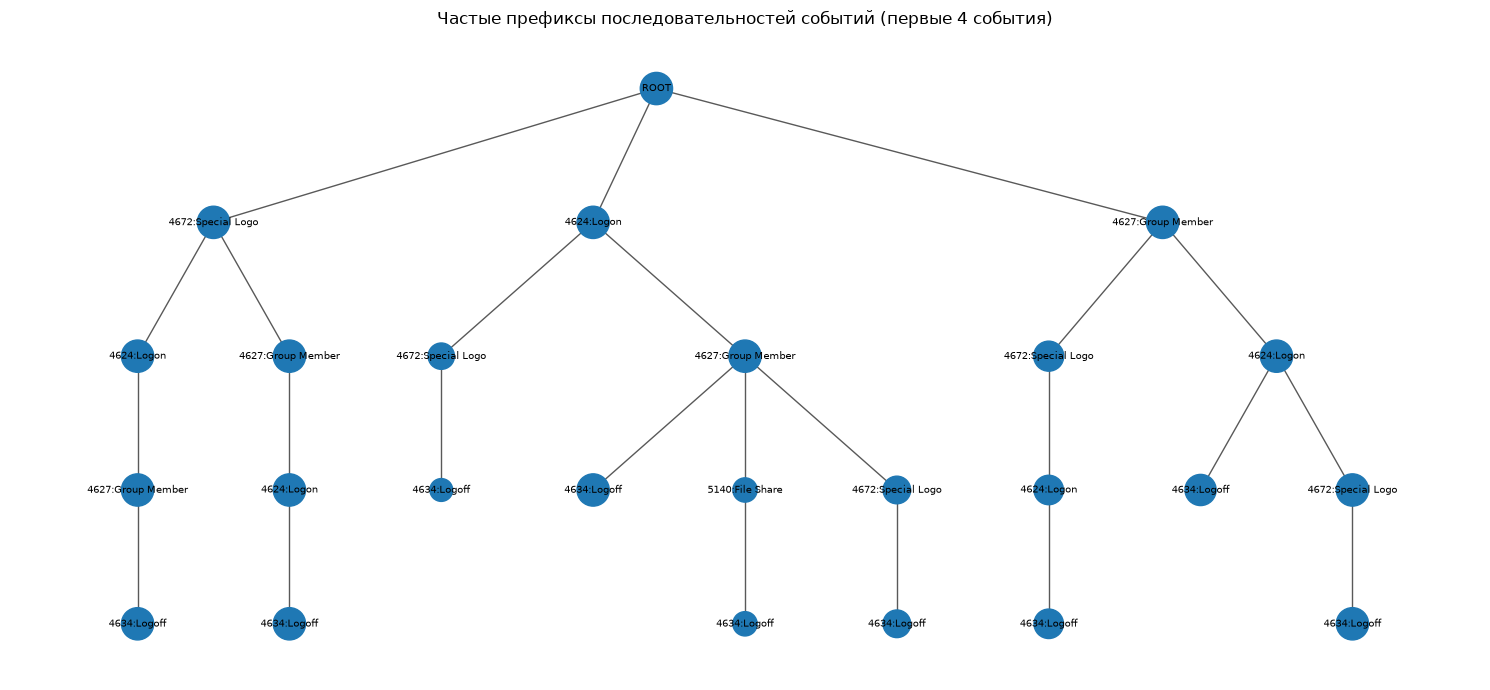

In [27]:
# Отдельно строим настоящее префиксное дерево последовательностей для визуализации.
# PrefixTree выше хранит контексты переходов для расчёта NLL; его граф состояний может содержать циклы,
# поэтому напрямую отображать его как дерево было некорректно.
def build_sequence_trie(sequences, max_depth=5):
    graph = nx.DiGraph()
    root = ()
    graph.add_node(root, count=0, token="ROOT")
    for sequence in sequences:
        prefix = root
        graph.nodes[prefix]["count"] += 1
        for token in sequence[:max_depth]:
            child = prefix + (token,)
            if child not in graph:
                graph.add_node(child, count=0, token=token)
            graph.add_edge(prefix, child, token=token)
            graph.nodes[child]["count"] += 1
            prefix = child
    return graph

viz_trie = build_sequence_trie(train_seqs[:300], max_depth=4)

# Оставляем самые частые ветви, сохраняя всех их предков, чтобы дерево не распадалось.
ranked_nodes = sorted(
    [n for n in viz_trie.nodes if n],
    key=lambda n: viz_trie.nodes[n]["count"],
    reverse=True
)
chosen = {()}
for node in ranked_nodes[:24]:
    for depth in range(1, len(node) + 1):
        chosen.add(node[:depth])
viz_sub = viz_trie.subgraph(chosen).copy()

pos_viz = tree_positions(viz_sub, root=())
labels_viz = {
    n: ("ROOT" if n == () else str(n[-1])[:17])
    for n in viz_sub.nodes()
}
plt.figure(figsize=(15, 7))
nx.draw_networkx_edges(viz_sub, pos_viz, arrows=False, width=1.0, alpha=0.65)
nx.draw_networkx_nodes(
    viz_sub, pos_viz,
    node_size=[180 + min(viz_sub.nodes[n]["count"], 20) * 18 for n in viz_sub.nodes()]
)
nx.draw_networkx_labels(viz_sub, pos_viz, labels_viz, font_size=7)
plt.title("Частые префиксы последовательностей событий (первые 4 события)")
plt.axis("off")
plt.tight_layout()
plt.show()

In [28]:
sess_df["nll"] = sess_df.tokens.apply(tree.neg_log_prob)
sess_df["nll_per_event"] = sess_df["nll"] / sess_df["len"].replace(0, np.nan)

def max_token_surprisal(sequence):
    if not sequence or not tree.vocab:
        return 0.0
    return max(tree.token_surprisal_at(sequence, i) for i in range(len(sequence)))

sess_df["max_surprisal"] = sess_df.tokens.apply(max_token_surprisal)
train_keys = set(train_sessions["session_key"].tolist())
scoring_sessions = sess_df[sess_df["len"].gt(0) & ~sess_df["session_key"].isin(train_keys)].copy()
if scoring_sessions.empty:
    print("Предупреждение: вне обучающей выборки нет сеансов; для демонстрации ранжируем все доступные сеансы.")
    scoring_sessions = sess_df[sess_df["len"].gt(0)].copy()

# Короткие сеансы с 1–2 событиями нестабильны для сравнения; используем их только если других нет.
long_enough = scoring_sessions[scoring_sessions["len"].ge(5)]
if not long_enough.empty:
    scoring_sessions = long_enough

top = scoring_sessions.sort_values(
    ["nll_per_event", "max_surprisal", "nll"], ascending=False
)
print(f"Сеансов для ранжирования: {len(top):,}. Обучающие сеансы исключены; основной показатель — средняя неожиданность на событие.")
display(top[["host", "user", "logon_type", "src_ip", "len", "nll", "nll_per_event", "max_surprisal", "session_key", "ts_start"]].head(20))

Сеансов для ранжирования: 49. Обучающие сеансы исключены; основной показатель — средняя неожиданность на событие.


,host,user,logon_type,src_ip,len,nll,nll_per_event,max_surprisal,session_key,ts_start
278,HFDC01.shire.com,IT001$,3.0,172.18.39.105,131,1199.286188,9.154856,9.401043,"(HFDC01.shire.com, 0x10dd8a6c)",2019-05-14 23:26:06.130000+00:00
141,HFDC01.shire.com,HR001$,3.0,172.18.39.106,131,1198.202666,9.146585,9.401043,"(HFDC01.shire.com, 0x10da07bd)",2019-05-14 22:55:59.375000+00:00
291,HFDC01.shire.com,HFDC01$,3.0,fe80::e086:822b:9735:45c8,19,144.776600,7.619821,9.401043,"(HFDC01.shire.com, 0x10ddd308)",2019-05-14 23:28:45.023000+00:00
105,HFDC01.shire.com,HFDC01$,3.0,fe80::e086:822b:9735:45c8,19,140.090226,7.373170,9.401043,"(HFDC01.shire.com, 0x10d96b02)",2019-05-14 22:48:42.965000+00:00
41,HFDC01.shire.com,HFDC01$,3.0,fe80::e086:822b:9735:45c8,19,139.987172,7.367746,9.401043,"(HFDC01.shire.com, 0x10d83b9c)",2019-05-14 22:33:42.249000+00:00
229,HFDC01.shire.com,HFDC01$,3.0,fe80::e086:822b:9735:45c8,19,139.987172,7.367746,9.401043,"(HFDC01.shire.com, 0x10dbf69b)",2019-05-14 23:13:44.226000+00:00
351,HFDC01.shire.com,HFDC01$,3.0,fe80::e086:822b:9735:45c8,19,139.987172,7.367746,9.401043,"(HFDC01.shire.com, 0x10e22697)",2019-05-14 23:43:47.881000+00:00
210,HFDC01.shire.com,HFDC01$,3.0,fe80::e086:822b:9735:45c8,19,139.696902,7.352469,9.401043,"(HFDC01.shire.com, 0x10db7b96)",2019-05-14 23:08:43.963000+00:00
84,HFDC01.shire.com,HFDC01$,3.0,fe80::e086:822b:9735:45c8,19,139.307038,7.331949,9.401043,"(HFDC01.shire.com, 0x10d908e1)",2019-05-14 22:43:42.715000+00:00
158,HFDC01.shire.com,HFDC01$,3.0,fe80::e086:822b:9735:45c8,19,139.307038,7.331949,9.401043,"(HFDC01.shire.com, 0x10da4274)",2019-05-14 22:58:43.458000+00:00


In [29]:
if len(top):
    worst = top.iloc[0]
    print(
        "Наиболее подозрительный кандидат по модели последовательностей:",
        f"host={worst.host}; user={worst.user}; начало={worst.ts_start};",
        f"событий={int(worst['len'])}; средняя неожиданность={worst.nll_per_event:.3f};",
        f"максимальная неожиданность события={worst.max_surprisal:.3f}"
    )
    for score, pos, token, ctx in tree.rare_transitions(worst.tokens, limit=10):
        print(f"позиция={pos + 1}; -log p={score:.2f}; событие={token}; контекст={ctx}")
else:
    print("Нет последовательностей для оценки.")

Наиболее подозрительный кандидат по модели последовательностей: host=HFDC01.shire.com; user=IT001$; начало=2019-05-14 23:26:06.130000+00:00; событий=131; средняя неожиданность=9.155; максимальная неожиданность события=9.401
позиция=130; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=129; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=128; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=127; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=126; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=125; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=124; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=123; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=122; -log p=9.40; событие=5145:Detailed File Share; контекст=()
позиция=121; -log p=9.40; событие=5145:Detailed File Share; контекст=()


In [30]:
# Подробные события самого высоко оценённого сеанса.
if len(top): display(df[df.session_key.map(lambda value: value == top.iloc[0].session_key)][["ts","host","event_id","task","user","image","command_line","message"]].head(100))

,ts,host,event_id,task,user,image,command_line,message
83298,2019-05-14 23:26:06.130000+00:00,HFDC01.shire.com,4627,Group Membership,IT001$,NaN,NaN,Group membership information.\n\nSubject:\n\tS...
83299,2019-05-14 23:26:06.130000+00:00,HFDC01.shire.com,4624,Logon,IT001$,NaN,NaN,An account was successfully logged on.\n\nSubj...
83300,2019-05-14 23:26:06.131000+00:00,HFDC01.shire.com,5140,File Share,IT001$,NaN,NaN,A network share object was accessed.\n\t\nSubj...
83301,2019-05-14 23:26:06.131000+00:00,HFDC01.shire.com,5145,Detailed File Share,IT001$,NaN,NaN,A network share object was checked to see whet...
83302,2019-05-14 23:26:06.132000+00:00,HFDC01.shire.com,5145,Detailed File Share,IT001$,NaN,NaN,A network share object was checked to see whet...
...,...,...,...,...,...,...,...,...
83428,2019-05-14 23:26:06.417000+00:00,HFDC01.shire.com,5145,Detailed File Share,IT001$,NaN,NaN,A network share object was checked to see whet...
83429,2019-05-14 23:26:06.418000+00:00,HFDC01.shire.com,5145,Detailed File Share,IT001$,NaN,NaN,A network share object was checked to see whet...
83431,2019-05-14 23:26:06.423000+00:00,HFDC01.shire.com,5145,Detailed File Share,IT001$,NaN,NaN,A network share object was checked to see whet...
83433,2019-05-14 23:26:06.427000+00:00,HFDC01.shire.com,5145,Detailed File Share,IT001$,NaN,NaN,A network share object was checked to see whet...


In [31]:
def anomalous_prefixes(seq,tree,top=5,ctx=3):
    return tree.rare_transitions(seq,limit=top)
if len(top): print(anomalous_prefixes(top.iloc[0].tokens,tree))

[(9.401043372798053, 129, '5145:Detailed File Share', ()), (9.401043372798053, 128, '5145:Detailed File Share', ()), (9.401043372798053, 127, '5145:Detailed File Share', ()), (9.401043372798053, 126, '5145:Detailed File Share', ()), (9.401043372798053, 125, '5145:Detailed File Share', ())]


In [32]:
display(top[["host", "user", "logon_type", "len", "nll", "nll_per_event", "max_surprisal", "ts_start", "ts_end"]].head(30))

,host,user,logon_type,len,nll,nll_per_event,max_surprisal,ts_start,ts_end
278,HFDC01.shire.com,IT001$,3.0,131,1199.286188,9.154856,9.401043,2019-05-14 23:26:06.130000+00:00,2019-05-14 23:29:10.226000+00:00
141,HFDC01.shire.com,HR001$,3.0,131,1198.202666,9.146585,9.401043,2019-05-14 22:55:59.375000+00:00,2019-05-14 22:59:02.182000+00:00
291,HFDC01.shire.com,HFDC01$,3.0,19,144.776600,7.619821,9.401043,2019-05-14 23:28:45.023000+00:00,2019-05-14 23:28:55.767000+00:00
105,HFDC01.shire.com,HFDC01$,3.0,19,140.090226,7.373170,9.401043,2019-05-14 22:48:42.965000+00:00,2019-05-14 22:48:53.693000+00:00
41,HFDC01.shire.com,HFDC01$,3.0,19,139.987172,7.367746,9.401043,2019-05-14 22:33:42.249000+00:00,2019-05-14 22:33:52.961000+00:00
229,HFDC01.shire.com,HFDC01$,3.0,19,139.987172,7.367746,9.401043,2019-05-14 23:13:44.226000+00:00,2019-05-14 23:13:54.922000+00:00
351,HFDC01.shire.com,HFDC01$,3.0,19,139.987172,7.367746,9.401043,2019-05-14 23:43:47.881000+00:00,2019-05-14 23:44:15.386000+00:00
210,HFDC01.shire.com,HFDC01$,3.0,19,139.696902,7.352469,9.401043,2019-05-14 23:08:43.963000+00:00,2019-05-14 23:08:54.704000+00:00
84,HFDC01.shire.com,HFDC01$,3.0,19,139.307038,7.331949,9.401043,2019-05-14 22:43:42.715000+00:00,2019-05-14 22:43:53.491000+00:00
158,HFDC01.shire.com,HFDC01$,3.0,19,139.307038,7.331949,9.401043,2019-05-14 22:58:43.458000+00:00,2019-05-14 22:58:54.154000+00:00


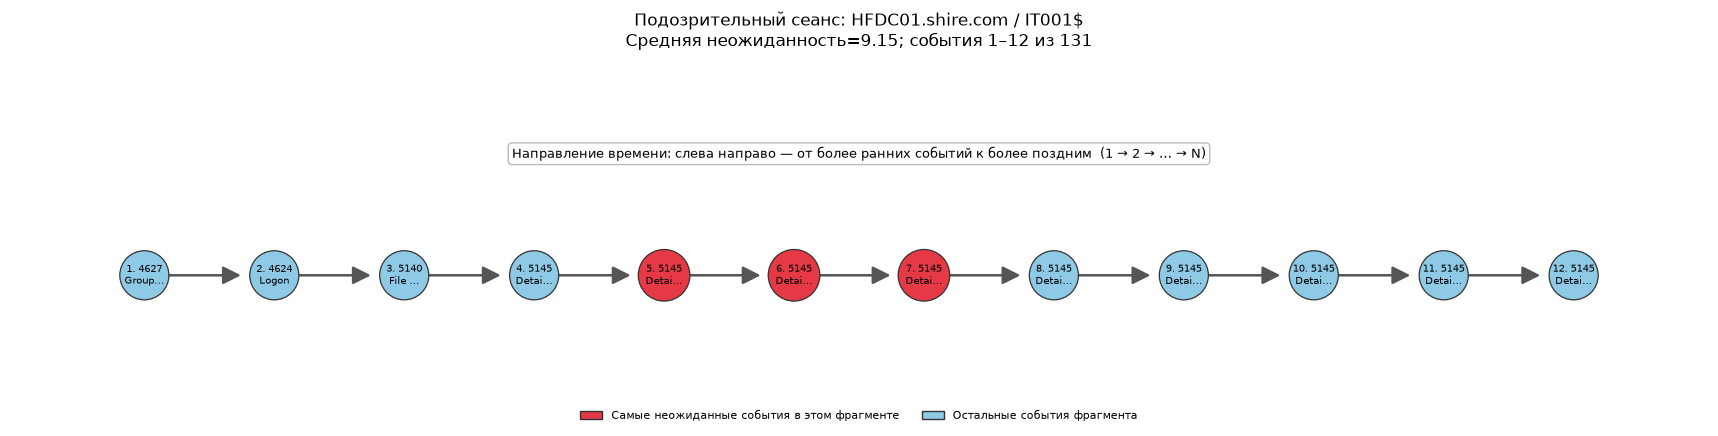

In [33]:
def plot_suspicious_session(session_row, max_events=12):
    """Показывает подозрительный фрагмент как хронологическую цепочку событий.

    Стрелка i -> i+1 означает только порядок по времени в сеансе,
    а не направление сетевого трафика и не доказанную причинно-следственную связь.
    """
    sequence = list(session_row["tokens"])
    if len(sequence) < 2:
        print("В подозрительном кандидате меньше двух событий; граф переходов не строится.")
        return

    # surprisal per event position; keep positions distinct even if token names repeat.
    scores_by_position = {
        int(position): float(score)
        for score, position, token, context in tree.rare_transitions(sequence, limit=len(sequence))
    }
    anchor = max(range(len(sequence)), key=lambda i: scores_by_position.get(i, 0.0))
    window_size = min(max_events, len(sequence))
    start = max(0, min(anchor - window_size // 2, len(sequence) - window_size))
    stop = start + window_size
    positions = list(range(start, stop))

    graph = nx.DiGraph()
    for i in positions:
        graph.add_node(i, token=sequence[i], surprisal=scores_by_position.get(i, 0.0))
    # Explicitly directed edge from each event to the next event in time.
    graph.add_edges_from(zip(positions[:-1], positions[1:]))
    x_gap = 1.4  # more space between nodes so arrowheads remain clearly visible
    pos = {i: (j * x_gap, 0) for j, i in enumerate(positions)}

    labels = {}
    for i in positions:
        token = str(sequence[i])
        event_id, _, task = token.partition(":")
        task = task.strip()
        if len(task) > 6:
            task = task[:5] + "…"
        labels[i] = f"{i + 1}. {event_id}\n{task}"

    # Highlight the most surprising quarter of events in the displayed window.
    ranked_positions = sorted(positions, key=lambda i: scores_by_position.get(i, 0.0), reverse=True)
    highlighted = set(ranked_positions[:max(1, math.ceil(len(positions) * 0.25))])
    node_colors = ["#e63946" if i in highlighted else "#8ecae6" for i in positions]
    node_sizes = [1380 if i in highlighted else 1250 for i in positions]

    fig_width = max(12, min(22, 1.5 * len(positions)))
    fig, ax = plt.subplots(figsize=(fig_width, 5.0))
    # Large, explicit arrowheads show the direction of the sequence at a glance.
    nx.draw_networkx_edges(
        graph, pos, ax=ax, arrows=True, arrowstyle="-|>", arrowsize=27,
        width=1.8, edge_color="#555555", connectionstyle="arc3,rad=0.0",
        min_source_margin=18, min_target_margin=24
    )
    nx.draw_networkx_nodes(
        graph, pos, ax=ax, node_size=node_sizes, node_color=node_colors,
        edgecolors="#333333", linewidths=0.9
    )
    nx.draw_networkx_labels(graph, pos, ax=ax, labels=labels, font_size=7)

    host = str(session_row.get("host", "UNKNOWN"))
    user = str(session_row.get("user", "UNKNOWN"))
    avg_score = float(session_row.get("nll_per_event", np.nan))
    fig.suptitle(
        f"Подозрительный сеанс: {host} / {user}\n"
        f"Средняя неожиданность={avg_score:.2f}; события {start + 1}–{stop} из {len(sequence)}",
        y=0.98, fontsize=12
    )
    # Direction label is retained even in viewers where arrowheads are hard to discern.
    ax.text(
        0.5, 0.88,
        "Направление времени: слева направо — от более ранних событий к более поздним  (1 → 2 → … → N)",
        transform=ax.transAxes, ha="center", va="center", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="#bbbbbb")
    )
    from matplotlib.patches import Patch
    ax.legend(handles=[
        Patch(facecolor="#e63946", edgecolor="#333333", label="Самые неожиданные события в этом фрагменте"),
        Patch(facecolor="#8ecae6", edgecolor="#333333", label="Остальные события фрагмента"),
    ], loc="lower center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False, fontsize=8)
    ax.set_ylim(-0.85, 1.15)
    ax.margins(x=0.04)
    ax.axis("off")
    fig.tight_layout(rect=(0.02, 0.08, 0.98, 0.90))
    plt.show()

if len(top):
    plot_suspicious_session(top.iloc[0], max_events=12)
else:
    print("Нет подозрительных кандидатов для отображения.")

## 4. Identity tracking: связывание локальных сеансов между узлами

Связываем локальные сеансы только по консервативным эвристикам: общий ненулевой `LogonGUID` при совпадении канонического пользователя, близком времени и отсутствии противоречия usable client IP; либо одна учётная запись + client IP + короткое окно времени для `LogonType` 3/10 на разных хостах. Случаи общего client IP без совпадения условий выводятся отдельно как pivot-кандидаты и автоматически не объединяются. Даже эти правила могут ошибочно связать независимые контексты.

**Интерпретация identity tracking.** `LogonGUID` и сочетание учётной записи/IP помогают связать локальные контексты между компьютерами, но правила объединения эвристические. Для подтверждения перехода между узлами нужно отдельно проверять исходные события входа и временные метки; совпадение только имени пользователя не считается достаточным основанием для объединения.


In [34]:
from networkx.utils import UnionFind
uf=UnionFind(range(len(sess_df)))
print("Локальных сеансов:",len(sess_df))

Локальных сеансов: 363


In [35]:
guid_to_idx=defaultdict(list)
null_guids = {"-", "0x0", "0", "{00000000-0000-0000-0000-000000000000}", "00000000-0000-0000-0000-000000000000"}
for i,r in sess_df.iterrows():
    if pd.notna(r.logon_guid):
        guid = str(r.logon_guid).strip().lower()
        if guid and guid not in null_guids:
            guid_to_idx[guid].append(i)
print("LogonGUID, встречающихся более одного раза:",sum(len(v)>1 for v in guid_to_idx.values()))

LogonGUID, встречающихся более одного раза: 25


In [36]:
{g:ix for g,ix in list(guid_to_idx.items())[:10]}

{'{03ba39f5-ea63-5ccb-0000-0020e4030000}': [0],
 '{5926a193-e2ce-cb62-863b-45f094c0ddec}': [2,
  26,
  33,
  35,
  36,
  42,
  43,
  45,
  46,
  47,
  48,
  54,
  55,
  56,
  61,
  62,
  63,
  68,
  70,
  72,
  78,
  79,
  80,
  85,
  86,
  88,
  89,
  92,
  95,
  99,
  100,
  101,
  106,
  107,
  108,
  109,
  111,
  118,
  121,
  122,
  123,
  128,
  129,
  131,
  136,
  146,
  148,
  152,
  153,
  154,
  159,
  160,
  161,
  164,
  166,
  173,
  183,
  184,
  185,
  191,
  192,
  193,
  194,
  195,
  203,
  204,
  205,
  206,
  211,
  212,
  213,
  215,
  218,
  220,
  222,
  224,
  225,
  230,
  231,
  232,
  238,
  241,
  243,
  247,
  248,
  249,
  254,
  255,
  256,
  257,
  258,
  260,
  262,
  263,
  264,
  269,
  270,
  271,
  273,
  283,
  284,
  285,
  286,
  287,
  292,
  293,
  294,
  295,
  297,
  302,
  308,
  309,
  310,
  316,
  317,
  318,
  319,
  320,
  321,
  322,
  323,
  324,
  329,
  330,
  331,
  333,
  334,
  336,
  345,
  346,
  347,
  352,
  353,
  354,
  3

In [37]:
joined_guid = 0
conflicting_guid_rows = []
guid_window = pd.Timedelta(minutes=30)
for guid, indices in guid_to_idx.items():
    ordered = sorted(indices, key=lambda idx: sess_df.loc[idx, "ts_start"])
    for pos, i in enumerate(ordered):
        for j in ordered[pos + 1:]:
            a, b = sess_df.loc[i], sess_df.loc[j]
            if pd.isna(a["ts_start"]) or pd.isna(b["ts_start"]):
                continue
            if b["ts_start"] - a["ts_start"] > guid_window:
                break
            if a["host"] == b["host"]:
                continue
            # A shared GUID is helpful, but a mismatch of canonical principal or client address is a conflict.
            user_a, user_b = a.get("user_key"), b.get("user_key")
            ip_a, ip_b = a.get("src_ip"), b.get("src_ip")
            ip_a_ok = pd.notna(ip_a) and is_usable_client_ip(ip_a)
            ip_b_ok = pd.notna(ip_b) and is_usable_client_ip(ip_b)
            if pd.isna(user_a) or pd.isna(user_b) or user_a != user_b or (ip_a_ok and ip_b_ok and str(ip_a) != str(ip_b)):
                conflicting_guid_rows.append({"guid": guid, "host_a": a["host"], "user_a": a["user"],
                                              "host_b": b["host"], "user_b": b["user"],
                                              "ip_a": ip_a, "ip_b": ip_b})
                continue
            if uf[i] != uf[j]:
                uf.union(i, j)
                joined_guid += 1
print(f"Объединений по LogonGUID после проверки пользователя/времени/IP: {joined_guid}")
print(f"Конфликтующих пар с общим LogonGUID для ручной проверки: {len(conflicting_guid_rows)}")
if conflicting_guid_rows:
    display(pd.DataFrame(conflicting_guid_rows).head(20))

Объединений по LogonGUID после проверки пользователя/времени/IP: 0
Конфликтующих пар с общим LogonGUID для ручной проверки: 0


In [38]:
joined_acct = 0
candidate = sess_df.dropna(subset=["user_key", "src_ip", "ts_start"]).copy()
# Logon Type 3 = network; 10 = remote interactive. Other types are too ambiguous for this pivot.
candidate = candidate.loc[candidate["logon_type"].isin([3, 10])].copy()

def is_usable_analysis_ip(value):
    """Use the same safe address scope as graph/GUID correlation."""
    return is_usable_client_ip(value)

candidate = candidate.loc[candidate["src_ip"].apply(is_usable_analysis_ip)].copy()
for (user, ip), group in candidate.groupby(["user_key", "src_ip"]):
    indices = list(group.sort_values("ts_start").index)
    for pos, idx_a in enumerate(indices):
        for idx_b in indices[pos + 1:]:
            delta = sess_df.loc[idx_b, "ts_start"] - sess_df.loc[idx_a, "ts_start"]
            if delta > pd.Timedelta(minutes=15):
                break
            if (sess_df.loc[idx_a, "host"] != sess_df.loc[idx_b, "host"] and uf[idx_a] != uf[idx_b]):
                uf.union(idx_a, idx_b)
                joined_acct += 1
print(f"Объединений по одинаковым учётной записи + client IP + времени (LogonType 3/10): {joined_acct}")

Объединений по одинаковым учётной записи + client IP + времени (LogonType 3/10): 5


In [39]:
# IP клиентов, наблюдавшиеся в успешных входах на каждый компьютер. Это НЕ инвентарь IP самих хостов.
host_client_ips_observed = (
    sess_df.dropna(subset=["host", "src_ip"])
    .groupby("host")["src_ip"]
    .apply(lambda values: set(str(x).strip() for x in values if str(x).strip() not in {"-", "None", "nan"}))
    .to_dict()
)
print(f"Компьютеров с наблюдавшимися client/source IP успешных входов: {len(host_client_ips_observed)}")

Компьютеров с наблюдавшимися client/source IP успешных входов: 4


In [40]:
host_client_ips_observed

{'ACCT001.shire.com': {'172.18.39.106'},
 'HFDC01.shire.com': {'127.0.0.1',
  '172.18.39.100',
  '172.18.39.102',
  '172.18.39.105',
  '172.18.39.106',
  '172.18.39.5',
  '::1',
  'fe80::e086:822b:9735:45c8'},
 'HR001.shire.com': {'127.0.0.1', '::1'},
 'IT001.shire.com': {'172.18.39.106', '::1'}}

In [41]:
# Дополнительный lead: одинаковый client/source IP у успешных сетевых/удалённых входов на разные компьютеры.
# Это не инвентарь IP самих хостов и не доказательство lateral movement; автоматического объединения здесь нет.
pivot_candidates = []
pivot_window = pd.Timedelta(minutes=30)
network_logons = sess_df.loc[sess_df["logon_type"].isin([3, 10])].dropna(subset=["src_ip", "ts_start", "user_key"]).copy()
network_logons = network_logons.loc[network_logons["src_ip"].apply(is_usable_analysis_ip)].copy()
for source_ip, group in network_logons.groupby("src_ip"):
    ordered = group.sort_values("ts_start")
    indices = list(ordered.index)
    for pos, idx_a in enumerate(indices):
        a = sess_df.loc[idx_a]
        for idx_b in indices[pos + 1:]:
            b = sess_df.loc[idx_b]
            delta = b["ts_start"] - a["ts_start"]
            if delta > pivot_window:
                break
            if a["host"] == b["host"] or uf[idx_a] == uf[idx_b]:
                continue
            pivot_candidates.append({
                "user_a": a["user"], "host_a": a["host"], "time_a": a["ts_start"], "logon_type_a": a["logon_type"],
                "user_b": b["user"], "host_b": b["host"], "time_b": b["ts_start"], "logon_type_b": b["logon_type"],
                "source_ip": source_ip, "time_delta_minutes": delta.total_seconds() / 60,
                "same_canonical_user": a["user_key"] == b["user_key"],
            })
pivot_candidates_df = pd.DataFrame(pivot_candidates)
joined_pivot = 0  # Deliberately no automatic merge without independent host/IP evidence.
print(f"Пар сетевых/удалённых входов с общим client/source IP для ручной проверки: {len(pivot_candidates_df):,}; автоматических слияний: {joined_pivot}")
if len(pivot_candidates_df):
    display(pivot_candidates_df.sort_values(["same_canonical_user", "time_delta_minutes"], ascending=[False, True]).drop_duplicates().head(50))
else:
    print("Совпадающие client/source IP в выбранном временном окне не найдены; это не доказывает отсутствия переходов между узлами.")

Пар сетевых/удалённых входов с общим client/source IP для ручной проверки: 104; автоматических слияний: 0


,user_a,host_a,time_a,logon_type_a,user_b,host_b,time_b,logon_type_b,source_ip,time_delta_minutes,same_canonical_user
92,pgustavo,ACCT001.shire.com,2019-05-14 22:54:37.851000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:11:17.946000+00:00,3.0,172.18.39.106,16.668250,True
68,pgustavo,IT001.shire.com,2019-05-14 22:54:15.012000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:11:17.946000+00:00,3.0,172.18.39.106,17.048900,True
93,pgustavo,ACCT001.shire.com,2019-05-14 22:54:37.851000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:12:24.638000+00:00,3.0,172.18.39.106,17.779783,True
69,pgustavo,IT001.shire.com,2019-05-14 22:54:15.012000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:12:24.638000+00:00,3.0,172.18.39.106,18.160433,True
94,pgustavo,ACCT001.shire.com,2019-05-14 22:54:37.851000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:13:31.351000+00:00,3.0,172.18.39.106,18.891667,True
70,pgustavo,IT001.shire.com,2019-05-14 22:54:15.012000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:13:31.351000+00:00,3.0,172.18.39.106,19.272317,True
95,pgustavo,ACCT001.shire.com,2019-05-14 22:54:37.851000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:14:27.619000+00:00,3.0,172.18.39.106,19.829467,True
71,pgustavo,IT001.shire.com,2019-05-14 22:54:15.012000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:14:27.619000+00:00,3.0,172.18.39.106,20.210117,True
98,pgustavo,ACCT001.shire.com,2019-05-14 22:54:37.851000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:15:18.749000+00:00,3.0,172.18.39.106,20.681633,True
74,pgustavo,IT001.shire.com,2019-05-14 22:54:15.012000+00:00,3.0,pgustavo,HFDC01.shire.com,2019-05-14 23:15:18.749000+00:00,3.0,172.18.39.106,21.062283,True


In [42]:
sess_df["identity_id"]=[uf[i] for i in sess_df.index]
print(f"Автоматические связи: проверенный LogonGUID={joined_guid}; account+IP/time для LogonType 3/10={joined_acct}; сетевой pivot=0 (только ручная проверка)")
print(f"Расширенных идентичностей: {sess_df.identity_id.nunique():,}; локальных сеансов: {len(sess_df):,}")

Автоматические связи: проверенный LogonGUID=0; account+IP/time для LogonType 3/10=5; сетевой pivot=0 (только ручная проверка)
Расширенных идентичностей: 358; локальных сеансов: 363


In [43]:
extended=sess_df.groupby("identity_id").agg(users=("user",lambda s:sorted(set(map(str,s))),),hosts=("host",lambda s:sorted(set(map(str,s))),),logon_types=("logon_type",lambda s:sorted({int(x) for x in s if pd.notna(x)})),ts_min=("ts_start","min"),ts_max=("ts_end","max"),n_local=("identity_id","count")).reset_index()
extended["span_s"]=(extended.ts_max-extended.ts_min).dt.total_seconds(); extended["multi_host"]=extended.hosts.apply(len).gt(1)
display(extended.sort_values(["multi_host","n_local"],ascending=[False,False]).head(20))

,identity_id,users,hosts,logon_types,ts_min,ts_max,n_local,span_s,multi_host
130,130,[pgustavo],"[ACCT001.shire.com, HFDC01.shire.com, IT001.sh...",[3],2019-05-14 22:54:15.012000+00:00,2019-05-14 23:33:07.890000+00:00,6,2332.878,True
0,0,[HR001$],[HR001.shire.com],[],2019-05-14 22:31:15.219000+00:00,2019-05-14 23:47:38.019000+00:00,1,4582.800,False
1,1,[SYSTEM],[HFDC01.shire.com],[5],2019-05-14 22:31:16.916000+00:00,2019-05-14 23:47:38.035000+00:00,1,4581.119,False
2,2,[HFDC01$],[HFDC01.shire.com],[3],2019-05-14 22:31:21.822000+00:00,2019-05-14 22:31:21.823000+00:00,1,0.001,False
3,3,[SYSTEM],[HR001.shire.com],[5],2019-05-14 22:31:26.793000+00:00,2019-05-14 23:47:41.686000+00:00,1,4574.893,False
4,4,[nmartha],[HR001.shire.com],[11],2019-05-14 22:31:26.896000+00:00,2019-05-14 22:31:27.076000+00:00,1,0.180,False
5,5,[nmartha],[HR001.shire.com],[11],2019-05-14 22:31:26.896000+00:00,2019-05-14 22:31:27.076000+00:00,1,0.180,False
6,6,[nmartha],[HR001.shire.com],[9],2019-05-14 22:31:26.911000+00:00,2019-05-14 23:44:19.273000+00:00,1,4372.362,False
7,7,[nmartha],[HR001.shire.com],[7],2019-05-14 22:31:27.010000+00:00,2019-05-14 22:31:27.077000+00:00,1,0.067,False
8,8,[nmartha],[HR001.shire.com],[7],2019-05-14 22:31:27.010000+00:00,2019-05-14 22:31:27.076000+00:00,1,0.066,False


## 5. Обогащение событий и графовый поиск аномалий

### 5.1. Классификация IP без GeoIP

В датасете нет подключённой GeoIP/ASN-базы, поэтому реальные страны и автономные системы не определяются. Ниже IP разделяются только по техническому типу адреса: private, loopback, link-local и другие специальные классы. Отсутствующий IP не считается подозрительной активностью сам по себе.


In [44]:
def classify_ip(ip):
    """Classify IP address scope only; no country or ASN is inferred."""
    if ip is None or pd.isna(ip) or str(ip).strip() in {"", "-"}:
        return ("MISSING", "UNKNOWN")
    try:
        addr = ipaddress.ip_address(str(ip).strip())
    except ValueError:
        return ("INVALID", "UNKNOWN")
    if addr.is_loopback:
        return ("LOOPBACK", "LOCAL")
    if addr.is_link_local:
        return ("LINK_LOCAL", "LOCAL")
    if addr.is_multicast:
        return ("MULTICAST", "SPECIAL")
    if addr.is_unspecified:
        return ("UNSPECIFIED", "SPECIAL")
    if addr.is_reserved:
        return ("RESERVED", "SPECIAL")
    if any(addr.version == net.version and addr in net for net in PRIVATE_IP_NETWORKS):
        return ("PRIVATE", "INTERNAL_NETWORK")
    if addr.version == 4 and addr in SHARED_CGNAT_NETWORK:
        return ("SHARED_CGNAT", "SHARED_ADDRESS_SPACE")
    if addr.is_global:
        return ("GLOBAL", "UNKNOWN_ASN")
    return ("NON_GLOBAL_SPECIAL", "SPECIAL")

sess_df[["ip_scope", "network_scope"]] = sess_df.src_ip.apply(lambda x: pd.Series(classify_ip(x)))
display(sess_df.groupby(["ip_scope", "network_scope"], dropna=False).size().rename("sessions").reset_index())

,ip_scope,network_scope,sessions
0,LINK_LOCAL,LOCAL,109
1,LOOPBACK,LOCAL,106
2,MISSING,UNKNOWN,32
3,PRIVATE,INTERNAL_NETWORK,116


In [45]:
# Показываем глобальные IP-адреса без присвоения страны или ASN: для этого нужна GeoIP-база.
display(sess_df[sess_df.ip_scope.eq("GLOBAL")][["host","user","logon_type","src_ip","ts_start","n_events"]].head(50))


,host,user,logon_type,src_ip,ts_start,n_events


In [46]:
# Профилируем только реально разобранные адреса; MISSING/INVALID и специальные неглобальные адреса не участвуют в профиле.
valid_ip_sessions = sess_df.loc[~sess_df.ip_scope.isin(["MISSING", "INVALID", "LOOPBACK", "LINK_LOCAL", "MULTICAST", "UNSPECIFIED", "RESERVED", "NON_GLOBAL_SPECIAL", "SHARED_CGNAT"])].copy()
user_ip_scope_profile = valid_ip_sessions.groupby("user_key").ip_scope.agg(lambda s: Counter(s)).to_dict()
display(pd.DataFrame([
    {"user": user, "valid_ip_scope_counts": dict(counts), "valid_sessions": sum(counts.values())}
    for user, counts in user_ip_scope_profile.items()
]).sort_values("valid_sessions", ascending=False).head(30))


,user,valid_ip_scope_counts,valid_sessions
4,nmartha,{'PRIVATE': 30},30
2,hr001$,{'PRIVATE': 20},20
5,pgustavo,{'PRIVATE': 18},18
1,hfdc01$,{'PRIVATE': 15},15
7,wecserver$,{'PRIVATE': 15},15
3,it001$,{'PRIVATE': 14},14
0,acct001$,{'PRIVATE': 2},2
6,wecserver,{'PRIVATE': 2},2


In [47]:
def ip_scope_anomaly(row, min_history=5, rare_fraction=0.10):
    """Flag a rare source-IP class only when one class dominates this user's history.

    This is a coarse class-based heuristic, not GeoIP and not an intrusion verdict.
    """
    scope = row["ip_scope"]
    if scope in {"MISSING", "INVALID", "LOOPBACK", "LINK_LOCAL", "MULTICAST", "UNSPECIFIED", "RESERVED", "NON_GLOBAL_SPECIAL", "SHARED_CGNAT"}:
        return False
    profile = user_ip_scope_profile.get(row["user_key"], Counter())
    total = sum(profile.values())
    if total < min_history:
        return False  # мало истории для профиля пользователя
    count = profile.get(scope, 0)
    dominant_count = max(profile.values(), default=0)
    rare_cutoff = max(1, int(math.floor(total * rare_fraction)))
    return count < dominant_count and count <= rare_cutoff and dominant_count >= min_history

sess_df["ip_scope_anomaly"] = sess_df.apply(ip_scope_anomaly, axis=1)
ip_scope_alerts = sess_df[sess_df.ip_scope_anomaly][["host","user","logon_type","src_ip","ip_scope","network_scope","ts_start"]]
print("Сеансов с редким IP-классом (только при достаточной истории и доминирующем обычном классе):", len(ip_scope_alerts))
display(ip_scope_alerts.head(50))

Сеансов с редким IP-классом (только при достаточной истории и доминирующем обычном классе): 0


,host,user,logon_type,src_ip,ip_scope,network_scope,ts_start


### 5.2. Граф взаимодействий и Isolation Forest

Граф связывает пользователя, компьютер, процесс и IP-адреса: адрес источника успешного входа берётся из Event ID 4624, а назначения сетевых соединений — из Sysmon Event ID 3 и Windows Filtering Platform. Isolation Forest помечает структурные выбросы по признакам графа. Красный узел означает **структурную необычность в построенном графе**, но сам по себе не доказывает атаку: нужно сопоставить его с событиями, временем и командными строками. Параметр `contamination=0.08` — выбранная доля выбросов модели, а не оценка доли заражённых объектов.


In [48]:
def canonical_graph_user(value, domain=None, host=None):
    """Канонизирует учётку; локальные встроенные учётки и пропуски ограничивает исходным хостом."""
    key = canonical_account_key(value, domain)
    host_key = str(host).strip().casefold() if host is not None and pd.notna(host) else "unknown-host"
    if key is None:
        return f"unknown@{host_key}"

    # These principals are local to each Windows host; treating them as one global identity
    # creates an artificial high-degree hub and can distort graph anomaly scores.
    local_principals = {
        "system", "nt authority\\system",
        "local service", "nt authority\\local service",
        "network service", "nt authority\\network service",
        "anonymous logon", "nt authority\\anonymous logon",
    }
    local_account = key in local_principals or bool(re.fullmatch(r"(?:dwm|umfd)-\d+", key))
    # A computer account such as HFDC01$ is host-scoped when it matches the source computer.
    host_short = host_key.split(".")[0]
    if key.split("\\")[-1] == f"{host_short}$":
        local_account = True
    return f"{key}@{host_key}" if local_account else key

def process_node_key(path, host=None):
    """Ключ образа включает хост и полный путь: одинаковый путь на двух ПК — не один процесс."""
    normalized = str(path).strip().replace("\\", "/").casefold()
    host_key = str(host).strip().casefold() if host is not None and pd.notna(host) else "unknown-host"
    return f"proc:{host_key}|{normalized}"

def build_security_graph(events,sessions):
    G=nx.MultiDiGraph()
    for _,r in sessions.iterrows():
        u=f"user:{canonical_graph_user(r['user'], r.get('domain'), r.get('host'))}"; h=f"host:{r['host']}"
        G.add_node(u,kind="user"); G.add_node(h,kind="host"); G.add_edge(u,h,etype="logon",logon_type=r["logon_type"])
        ip=r.get("src_ip")
        # Loopback/link-local/invalid addresses are summarized in the IP section but not used
        # as cross-entity graph pivots, because they can create artificial high-degree hubs.
        if pd.notna(ip) and ip and str(ip)!="-" and is_usable_client_ip(ip):
            inode=f"ip:{str(ip).strip()}"; G.add_node(inode,kind="ip"); G.add_edge(inode,u,etype="source_ip")
    sysmon_mask = (
        events["source_name"].fillna("").str.contains("Sysmon", case=False, regex=False)
        | events["log_name"].fillna("").str.contains("Sysmon", case=False, regex=False)
    )
    security_mask = (
        events["source_name"].fillna("").str.contains("Security-Auditing", case=False, regex=False)
        | events["log_name"].fillna("").str.fullmatch("Security", case=False, na=False)
    )
    process_create_mask = (sysmon_mask & events["event_id"].eq(1)) | (security_mask & events["event_id"].eq(4688))
    process_create_events = events[process_create_mask].dropna(subset=["image"])
    for _,r in process_create_events.iterrows():
        user=f"user:{canonical_graph_user(r['user'], r.get('domain'), r.get('host'))}"
        proc=process_node_key(r["image"], r["host"])
        host=f"host:{r['host']}"
        G.add_node(user,kind="user")
        G.add_node(proc,kind="proc",image_path=str(r["image"]))
        G.add_node(host,kind="host")
        G.add_edge(user,proc,etype="exec")
        G.add_edge(proc,host,etype="executed_on")
        parent_path = r.get("parent_image")
        if pd.notna(parent_path) and str(parent_path).strip():
            parent_proc = process_node_key(parent_path, r["host"])
            G.add_node(parent_proc,kind="proc",image_path=str(parent_path))
            G.add_edge(parent_proc,proc,etype="parent_process")
    # Add actual network destinations from Sysmon NetworkConnect (3) and Windows Filtering Platform.
    # The source endpoint is not treated as a client login IP; direction here is a network connection.
    wfp_mask = security_mask & events["event_id"].isin([5156, 5157])
    net_event_mask = (sysmon_mask & events["event_id"].eq(3)) | wfp_mask
    net_events = events[net_event_mask]
    for _, r in net_events.iterrows():
        host_value = r.get("host")
        if pd.isna(host_value) or not str(host_value).strip():
            continue
        host = f"host:{host_value}"
        G.add_node(host, kind="host")
        dst_ip = r.get("dst_ip")
        if pd.isna(dst_ip) or not str(dst_ip).strip() or not is_usable_client_ip(dst_ip):
            continue
        destination = f"ip:{str(dst_ip).strip()}"
        G.add_node(destination, kind="ip")

        image_path = r.get("image")
        if pd.isna(image_path) or not str(image_path).strip():
            image_path = r.get("application")
        event_id = int(r["event_id"])
        connection_type = {3: "network_connects_to", 5156: "network_allowed_to", 5157: "network_blocked_to"}.get(event_id, "network_connection")
        if pd.notna(image_path) and str(image_path).strip() not in {"", "-", "None", "nan"}:
            process = process_node_key(image_path, host_value)
            G.add_node(process, kind="proc", image_path=str(image_path))
            G.add_edge(process, host, etype="network_process_on_host", event_id=event_id)
            G.add_edge(process, destination, etype=connection_type,
                       destination_port=r.get("dst_port"), event_id=event_id)
            raw_user = r.get("user")
            if pd.notna(raw_user) and canonical_account_key(raw_user, r.get("domain")) is not None:
                actor = f"user:{canonical_graph_user(raw_user, r.get('domain'), host_value)}"
                G.add_node(actor, kind="user")
                G.add_edge(actor, process, etype="network_actor", event_id=int(r["event_id"]))
        else:
            G.add_edge(host, destination, etype=connection_type,
                       destination_port=r.get("dst_port"), event_id=event_id)
    return G
G=build_security_graph(df,sess_df)
print(f"Граф: |V|={G.number_of_nodes():,}, |E|={G.number_of_edges():,}")
print("Типы вершин:",dict(Counter(d.get("kind","?") for _,d in G.nodes(data=True))))

Граф: |V|=262, |E|=30,445
Типы вершин: {'user': 28, 'host': 4, 'ip': 82, 'proc': 148}


In [49]:
G_simple = nx.Graph(G)

def node_features(node):
    degree = G_simple.degree(node)
    neighbors = list(G_simple.neighbors(node))
    kinds = Counter(G_simple.nodes[n].get("kind", "?") for n in neighbors)
    clustering = nx.clustering(G_simple, node) if degree > 1 else 0.0
    out_logons = sum(1 for _, _, data in G.out_edges(node, data=True) if data.get("etype") == "logon")
    return [
        degree,
        clustering,
        out_logons,
        sum(G_simple.nodes[n].get("kind") == "proc" for n in neighbors),
        sum(G_simple.nodes[n].get("kind") == "ip" for n in neighbors),
        kinds.get("user", 0),
        kinds.get("host", 0),
    ]

nodes = list(G.nodes())
if len(nodes) >= 10:
    X = np.asarray([node_features(node) for node in nodes], dtype=float)
    # contamination=0.08 — выбранная доля ожидаемых выбросов для ранжирования, не известная доля атак.
    iso = IsolationForest(contamination=0.08, random_state=RANDOM_STATE, n_estimators=150)
    predictions = iso.fit_predict(X)
    scores = -iso.score_samples(X)  # bigger means more unusual
    node_scores = pd.DataFrame({
        "node": nodes,
        "kind": [G.nodes[node].get("kind") for node in nodes],
        "score": scores,
        "is_anomaly": predictions == -1,
    }).sort_values(["is_anomaly", "score"], ascending=[False, False])
else:
    node_scores = pd.DataFrame(columns=["node", "kind", "score", "is_anomaly"])
    print("В графе слишком мало вершин для устойчивой оценки Isolation Forest (нужно не менее 10).")

display(node_scores.head(30))
print("Вершин, помеченных Isolation Forest как выбросы:", int(node_scores["is_anomaly"].sum()) if not node_scores.empty else 0)

,node,kind,score,is_anomaly
3,host:HFDC01.shire.com,host,0.764096,True
1,host:HR001.shire.com,host,0.713751,True
4,user:hfdc01$@hfdc01.shire.com,user,0.696596,True
12,user:pgustavo,user,0.694595,True
36,proc:hr001.shire.com|c:/windows/system32/micro...,proc,0.657722,True
61,proc:hfdc01.shire.com|c:/windows/system32/svch...,proc,0.654264,True
6,user:nmartha,user,0.649885,True
159,proc:hr001.shire.com|/device/harddiskvolume2/w...,proc,0.647132,True
33,proc:hr001.shire.com|c:/windows/system32/svcho...,proc,0.636202,True
13,ip:172.18.39.5,ip,0.630770,True


Вершин, помеченных Isolation Forest как выбросы: 21


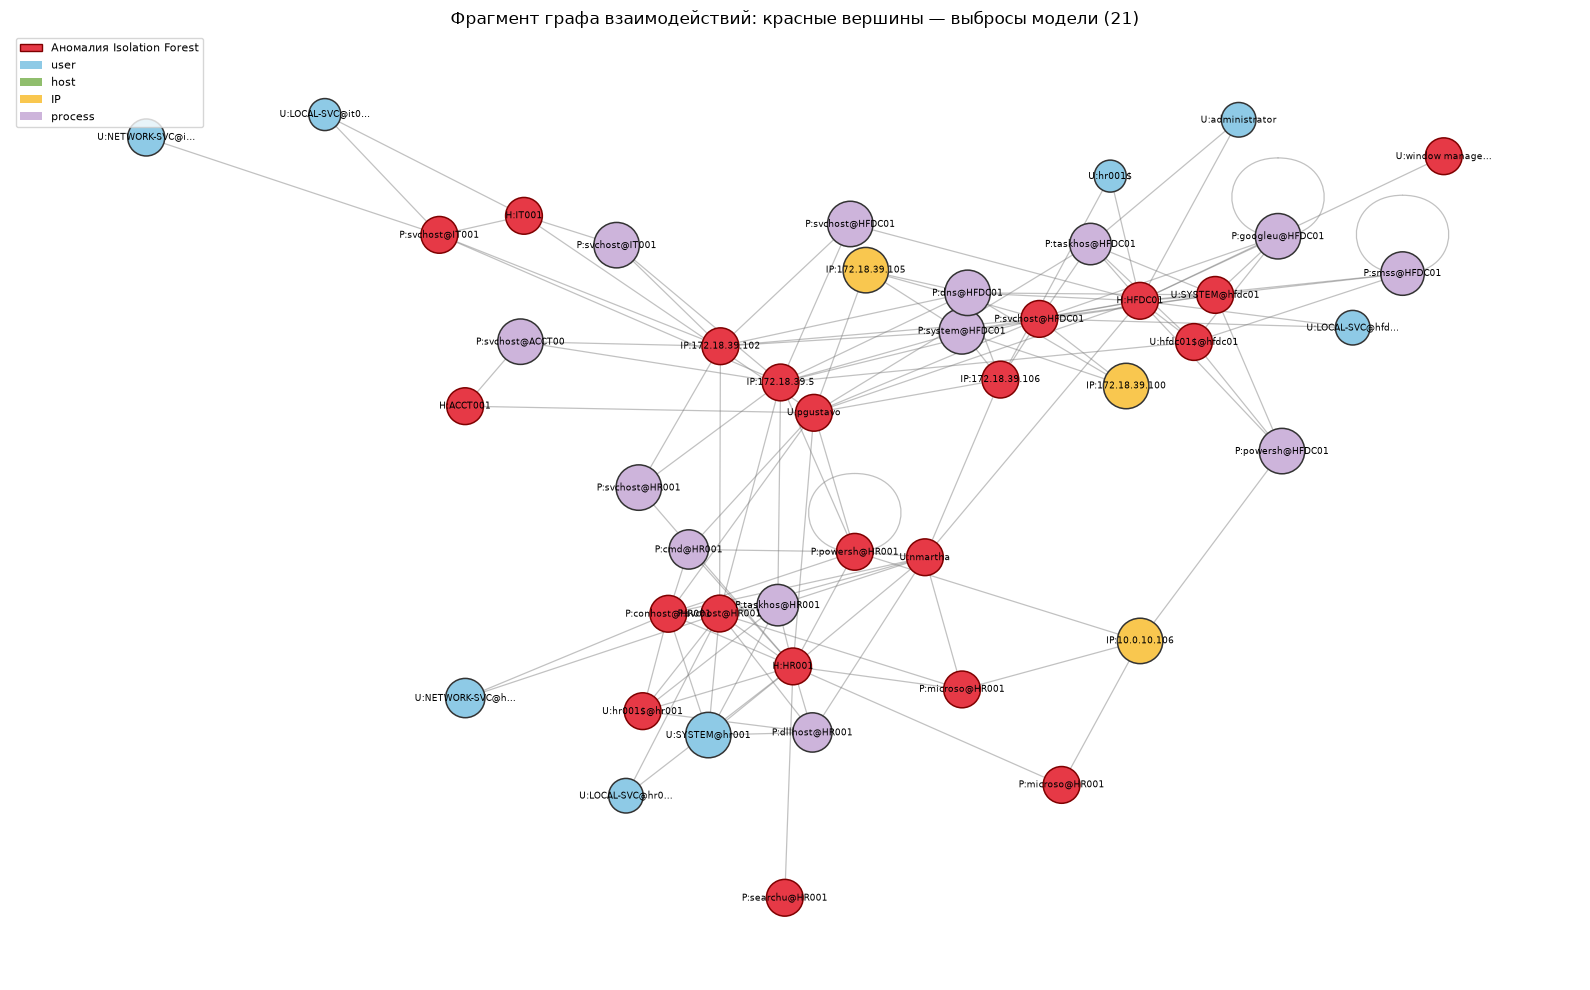

Вершины на графе: 45 | рёбра: 123
Красных вершин (выбросов Isolation Forest) в показанном фрагменте: 21


,node,kind,score,is_anomaly
3,host:HFDC01.shire.com,host,0.764096,True
1,host:HR001.shire.com,host,0.713751,True
4,user:hfdc01$@hfdc01.shire.com,user,0.696596,True
12,user:pgustavo,user,0.694595,True
36,proc:hr001.shire.com|c:/windows/system32/micro...,proc,0.657722,True
61,proc:hfdc01.shire.com|c:/windows/system32/svch...,proc,0.654264,True
6,user:nmartha,user,0.649885,True
159,proc:hr001.shire.com|/device/harddiskvolume2/w...,proc,0.647132,True
33,proc:hr001.shire.com|c:/windows/system32/svcho...,proc,0.636202,True
13,ip:172.18.39.5,ip,0.630770,True


In [50]:
# Красный цвет означает, что Isolation Forest пометил вершину как структурный выброс.
# Остальные вершины сохраняют цвет типа сущности, чтобы структура оставалась читаемой.
from matplotlib.patches import Patch

if not node_scores.empty and G_simple.number_of_nodes():
    score_lookup = node_scores.set_index("node")["score"].to_dict()
    anomaly_lookup = node_scores.set_index("node")["is_anomaly"].astype(bool).to_dict()
    components = list(nx.connected_components(G_simple))
    component = max(
        components,
        key=lambda comp: (sum(anomaly_lookup.get(node, False) for node in comp), len(comp))
    )

    flagged = sorted(
        [node for node in component if anomaly_lookup.get(node, False)],
        key=lambda node: score_lookup.get(node, 0.0),
        reverse=True,
    )
    # Если в выбранной компоненте нет выбросов, показываем её самые высоко оценённые вершины,
    # но не перекрашиваем их в красный без метки модели.
    seeds = flagged[:12] if flagged else sorted(
        component, key=lambda node: score_lookup.get(node, 0.0), reverse=True
    )[:12]

    selected = set(seeds)
    for node in seeds:
        selected.update(neighbor for neighbor in G_simple.neighbors(node) if neighbor in component)

    if len(selected) > 45:
        non_seeds = selected - set(seeds)
        ranked_neighbors = sorted(
            non_seeds,
            key=lambda node: (score_lookup.get(node, 0.0), G_simple.degree(node)),
            reverse=True,
        )
        selected = set(seeds) | set(ranked_neighbors[:max(0, 45 - len(seeds))])

    H = G_simple.subgraph(selected).copy()
    if H.number_of_nodes():
        pos = nx.spring_layout(H, seed=RANDOM_STATE, k=1.25, iterations=250)
        kind_colors = {
            "user": "#8ecae6",
            "host": "#90be6d",
            "ip": "#f9c74f",
            "proc": "#cdb4db",
        }
        node_colors = [
            "#e63946" if anomaly_lookup.get(node, False)
            else kind_colors.get(G.nodes[node].get("kind"), "#cccccc")
            for node in H.nodes()
        ]
        node_sizes = [
            700 if anomaly_lookup.get(node, False)
            else 350 + 90 * min(G_simple.degree(node), 8)
            for node in H.nodes()
        ]
        edge_colors = ["#7f0000" if anomaly_lookup.get(node, False) else "#333333" for node in H.nodes()]
        def compact_node_label(node):
            kind, _, value = str(node).partition(":")
            prefix = {"user": "U:", "host": "H:", "ip": "IP:", "proc": "P:"}.get(kind, "")
            if kind == "host":
                value = value.split(".")[0]
            elif kind == "proc":
                # The graph key includes the full host and path; the compact label keeps the host visible
                # so identically named executables on different computers are not visually conflated.
                if "|" in value:
                    host_part, path_part = value.split("|", 1)
                    short_host = host_part.split(".")[0].upper()[:6]
                else:
                    path_part, short_host = value, "HOST"
                parts = [part for part in path_part.replace("\\", "/").split("/") if part]
                executable = parts[-1] if parts else path_part
                executable = executable.rsplit(".", 1)[0] if "." in executable else executable
                value = f"{executable[:7]}@{short_host}"
            elif kind == "user" and "@" in value:
                account, scoped_host = value.rsplit("@", 1)
                short_host = scoped_host.split(".")[0]
                account_short = {
                    "nt authority\\system": "SYSTEM",
                    "nt authority\\local service": "LOCAL-SVC",
                    "nt authority\\network service": "NETWORK-SVC",
                    "local service": "LOCAL-SVC",
                    "network service": "NETWORK-SVC",
                    "system": "SYSTEM",
                }.get(account, account.rsplit("\\", 1)[-1])
                value = f"{account_short}@{short_host}"
            available = max(7, 16 - len(prefix))
            if len(value) > available:
                value = value[:available - 1] + "…"
            return prefix + value

        labels = {node: compact_node_label(node) for node in H.nodes()}

        plt.figure(figsize=(16, 10))
        nx.draw_networkx_edges(H, pos, edge_color="#777777", alpha=0.45, width=0.9)
        nx.draw_networkx_nodes(H, pos, node_color=node_colors, node_size=node_sizes,
                               edgecolors=edge_colors, linewidths=1.1)
        nx.draw_networkx_labels(H, pos, labels=labels, font_size=6.5)

        legend_items = [
            Patch(facecolor="#e63946", edgecolor="#7f0000", label="Аномалия Isolation Forest"),
            Patch(facecolor=kind_colors["user"], label="user"),
            Patch(facecolor=kind_colors["host"], label="host"),
            Patch(facecolor=kind_colors["ip"], label="IP"),
            Patch(facecolor=kind_colors["proc"], label="process"),
        ]
        plt.legend(handles=legend_items, loc="upper left", frameon=True, fontsize=8)
        n_red = sum(anomaly_lookup.get(node, False) for node in H.nodes())
        plt.title(f"Фрагмент графа взаимодействий: красные вершины — выбросы модели ({n_red})")
        plt.axis("off")
        plt.tight_layout()
        plt.show()

        print("Вершины на графе:", H.number_of_nodes(), "| рёбра:", H.number_of_edges())
        print("Красных вершин (выбросов Isolation Forest) в показанном фрагменте:", n_red)
        if n_red == 0:
            print("В выбранной компоненте нет помеченных моделью выбросов; цвет остальных узлов не маскирует score.")
        display(node_scores[node_scores["is_anomaly"]].head(15)[["node", "kind", "score", "is_anomaly"]])
    else:
        print("Не удалось выделить связный фрагмент для отображения.")
else:
    print("Нет оценённых вершин для графового отображения.")

## 6. Знакомство с MSTICPy и OTRF Security Datasets (Mordor)

Этот блок сохранён как необязательная демонстрация из шаблона. Он не требуется для анализа Empire APT3 и может обращаться к внешним источникам. Подключение по умолчанию отключено.

In [51]:
try:
    import msticpy
    print("MSTICPy установлен:",getattr(msticpy,"__version__","версия не определена"))
except ImportError:
    print("MSTICPy не установлен; блок Mordor необязателен.")

MSTICPy не установлен; блок Mordor необязателен.


In [52]:
ENABLE_MORDOR_CONNECT=False
if ENABLE_MORDOR_CONNECT:
    from msticpy.data import QueryProvider
    mdr_data=QueryProvider("Mordor"); mdr_data.connect()
    print("Провайдер Mordor подключён.")
else: print("Подключение к Mordor отключено по умолчанию; основной анализ Empire APT3 завершён независимо от него.")

Подключение к Mordor отключено по умолчанию; основной анализ Empire APT3 завершён независимо от него.


In [53]:
if "mdr_data" in globals():
    try: display(mdr_data.list_queries())
    except Exception as exc: print("Не удалось получить список запросов:",repr(exc))
else: print("Список запросов недоступен: Mordor не подключён.")

Список запросов недоступен: Mordor не подключён.


In [54]:
if "mdr_data" in globals():
    try:
        result=mdr_data.atomic.windows.collection.host.msf_record_mic()
        display(result.head() if hasattr(result,"head") else result)
    except Exception as exc: print("Примерный запрос недоступен в текущей конфигурации:",repr(exc))
else: print("Пример запроса пропущен: внешнее подключение отключено.")

Пример запроса пропущен: внешнее подключение отключено.


## 7. Итоговые результаты и ограничения

Итог должен формироваться из рассчитанных результатов после `Run All`, а не из заранее записанных предположений. Сначала рассматриваются совпадения по конкретным индикаторам и контексты с необычными последовательностями, затем — связи между пользователями, IP, компьютерами и процессами.

Важно: редкий Event ID, необычная последовательность, частный IP, отсутствие IP или красный узел Isolation Forest сами по себе не доказывают компрометацию. Проверяйте исходное сообщение, командную строку, процесс-родитель, пользователя, компьютер и близкие по времени события. Эвристики не заменяют ручную верификацию.


Результаты не должны подменяться фиксированным списком «известных» артефактов: конкретные количества и первые кандидаты ниже пересчитываются для загруженного файла.


In [55]:
# Контрольная сводка после выполнения всех предыдущих ячеек.
summary = {
    "events": len(df),
    "invalid_json_lines": invalid_json_lines,
    "non_object_json_lines": non_object_json_lines,
    "hosts": df.host.nunique(dropna=True),
    "sources": df.source_name.nunique(dropna=True),
    "event_ids": df.event_id.nunique(dropna=True),
    "contexts_with_LogonId": len(sess_df),
    "extended_identities": sess_df.identity_id.nunique() if "identity_id" in sess_df else 0,
    "graph_nodes": G.number_of_nodes() if "G" in globals() else 0,
    "graph_edges": G.number_of_edges() if "G" in globals() else 0,
    "PowerShell_source_events": len(ps_df) if "ps_df" in globals() else 0,
    "WMI_Activity_events": len(wmi_events) if "wmi_events" in globals() else 0,
    "Windows_Filtering_Platform_events": len(firewall_events) if "firewall_events" in globals() else 0,
    "Service_install_or_SCM_events": len(service_events) if "service_events" in globals() else 0,
    "shared_client_ip_cross_host_candidates": len(pivot_candidates_df) if "pivot_candidates_df" in globals() else 0,
    "rule_based_candidate_events": len(hunt_hits) if "hunt_hits" in globals() else 0,
    "IP_scope_heuristic_alerts": len(ip_scope_alerts) if "ip_scope_alerts" in globals() else 0,
    "graph_structural_outliers": int(node_scores["is_anomaly"].sum()) if "node_scores" in globals() and "is_anomaly" in node_scores else 0,
}
display(pd.Series(summary, name="value").to_frame())

print("\n=== Кандидат по модели последовательностей ===")
if "top" in globals() and len(top):
    best = top.iloc[0]
    print(f"Компьютер: {best.host}; пользователь: {best.user}; начало: {best.ts_start}; конец: {best.ts_end}")
    print(f"Событий: {int(best['len'])}; средняя неожиданность на событие: {best.nll_per_event:.3f}; максимум по одному событию: {best.max_surprisal:.3f}")
    print("Это ранжированный кандидат, а не подтверждённая атака. Проверяйте вывод предыдущей ячейки с событиями и строки с наибольшей неожиданностью.")
else:
    print("Нет последовательностей для ранжирования.")

print("\n=== Находки по правилам и источникам телеметрии ===")
if "category_counts" in globals() and not category_counts.empty:
    matched_categories = category_counts[category_counts["matching_events"] > 0]
    print("Категории индикаторов с совпадениями:")
    display(matched_categories.head(10) if len(matched_categories) else matched_categories)
else:
    print("Сводка строковых индикаторов не сформирована.")

if "hunt_hits" in globals() and not hunt_hits.empty:
    print("Примеры событий-кандидатов для ручной проверки:")
    show_cols = [c for c in ["ts", "host", "source_name", "event_id", "task", "user", "image", "parent_image", "command_line", "target_image", "target_object", "service_name", "service_path", "script_block_text", "matched_categories", "review_priority"] if c in hunt_hits.columns]
    display(hunt_hits[show_cols].head(20))
    print("Кандидаты по исходному компьютеру:")
    display(hunt_hits.groupby("host").size().sort_values(ascending=False).rename("candidate_events").to_frame().head(10))
    timed_hits = hunt_hits.dropna(subset=["ts"]).copy()
    if len(timed_hits):
        timed_hits["time_bin_30m"] = timed_hits["ts"].dt.floor("30min")
        print("Интервалы по 30 минутам с наибольшим числом совпадений:")
        display(timed_hits.groupby(["host", "time_bin_30m"]).size().sort_values(ascending=False).rename("candidate_events").reset_index().head(10))
else:
    print("Строковых совпадений по заданным правилам нет; это не доказывает отсутствие атаки.")

if "lsass_access" in globals():
    print(f"Sysmon Event ID 10 с целью LSASS: {len(lsass_access):,}")
else:
    print("Выборка событий доступа к LSASS не сформирована (Event ID 10 отсутствует).")

print("\n=== Интерпретация ===")
print("Порядок ручной проверки: (1) совпадения по PowerShell/процессам/службам/автозапуску; (2) Sysmon Process Access к LSASS; (3) сетевые соединения, особенно с необычным процессом/назначением; (4) самые неожиданные последовательности; (5) красные узлы графа. Количество строк-кандидатов не равно числу уникальных инцидентов.")
print("GLOBAL IP не означает вредоносность; страна и ASN не выводятся без GeoIP-базы. Редкость, совпадение сигнатуры или оценка модели — лишь основание для расследования, а не доказательство компрометации.")


print("\n=== Итоговый вывод по данным ===")
valid_ts = df["ts"].dropna()
if len(valid_ts):
    print(f"Период: {valid_ts.min()} — {valid_ts.max()} (UTC). Событий: {len(df):,}; компьютеров: {df['host'].nunique(dropna=True)}; источников телеметрии: {df['source_name'].nunique(dropna=True)}; типов Event ID: {df['event_id'].nunique(dropna=True)}.")
else:
    print(f"Событий: {len(df):,}; валидных временных меток нет — временные выводы делать нельзя.")
print("Наиболее представленные источники:")
display(df["source_name"].fillna("UNKNOWN").value_counts().head(8).rename_axis("source_name").to_frame("events"))
print("Это многослойная телеметрия; дальнейший вывод не ограничивается только журналом Security.")
print(f"Событий неуспешного входа (4625): {len(failed_logons) if 'failed_logons' in globals() else 0}; событий изменения учётных записей/групп из проверенного перечня: {len(account_changes) if 'account_changes' in globals() else 0}.")
print(f"Событий-кандидатов по строковым индикаторам: {len(hunt_hits) if 'hunt_hits' in globals() else 0}; совпавших категорий индикаторов: {int((category_counts['matching_events'] > 0).sum()) if 'category_counts' in globals() and not category_counts.empty else 0}.")
if "hunt_hits" in globals() and not hunt_hits.empty:
    first_hit = hunt_hits.sort_values(["review_priority", "ts"], ascending=[False, True]).iloc[0]
    hit_text = ""
    for field in ["message", "script_block_text", "command_line", "service_path", "target_object"]:
        value = first_hit.get(field)
        if pd.notna(value) and str(value).strip().lower() not in {"", "nan", "none", "null", "-"}:
            hit_text = str(value)
            break
    hit_text = " ".join(hit_text.split())[:260]
    print(f"Первым по очереди ручной проверки идёт: {first_hit['ts']} | {first_hit['host']} | Event ID {int(first_hit['event_id']) if pd.notna(first_hit['event_id']) else 'NA'} | {first_hit.get('matched_categories', '')}.")
    if hit_text:
        print("Фрагмент исходного события:", hit_text)
else:
    print("Сигнатурных совпадений нет; это не исключает обход сигнатур или неполноту телеметрии.")
if "top" in globals() and len(top):
    best = top.iloc[0]
    print(f"Модель последовательностей выделила для проверки сеанс {best['host']} / {best['user']} ({int(best['len'])} событий; средняя неожиданность {best['nll_per_event']:.3f}). Это относительный кандидат, а не подтверждение атаки.")
if "ip_scope_alerts" in globals():
    print(f"Эвристика редкого класса IP (не геолокация) отметила {len(ip_scope_alerts)} сеансов; она использует тип адреса, а не геолокацию.")
if "node_scores" in globals() and not node_scores.empty:
    print(f"Isolation Forest пометил {int(node_scores['is_anomaly'].sum())} из {len(node_scores)} вершин как структурные выбросы при contamination=0.08. Это параметр модели, не оценка доли атакующих объектов.")
print("Итог: в качестве приоритетов расследования используются конкретные совпадения в исходных событиях, контексты с необычными последовательностями и связанные графовые сущности. Любой кандидат требует проверки процесса, команды, пользователя, хоста и временного окружения.")


,value
events,121659
invalid_json_lines,0
non_object_json_lines,0
hosts,4
sources,14
event_ids,86
contexts_with_LogonId,363
extended_identities,358
graph_nodes,262
graph_edges,30445



=== Кандидат по модели последовательностей ===
Компьютер: HFDC01.shire.com; пользователь: IT001$; начало: 2019-05-14 23:26:06.130000+00:00; конец: 2019-05-14 23:29:10.226000+00:00
Событий: 131; средняя неожиданность на событие: 9.155; максимум по одному событию: 9.401
Это ранжированный кандидат, а не подтверждённая атака. Проверяйте вывод предыдущей ячейки с событиями и строки с наибольшей неожиданностью.

=== Находки по правилам и источникам телеметрии ===
Категории индикаторов с совпадениями:


,category,matching_events
0,PowerShell: кодированная команда / загрузка / ...,33990
3,Закрепление / служба / автозапуск,1013
4,Разведка / удалённое выполнение,330
1,Скриптовые хосты / LOLBin,319
2,Доступ к учётным данным / LSASS,117


Примеры событий-кандидатов для ручной проверки:


,ts,host,source_name,event_id,task,user,image,parent_image,command_line,target_image,target_object,service_name,service_path,script_block_text,matched_categories,review_priority
8316,2019-05-14 22:32:23.415000+00:00,HR001.shire.com,Microsoft-Windows-Sysmon,1,Process Create (rule: ProcessCreate),SHIRE\nmartha,C:\Windows\System32\WindowsPowerShell\v1.0\pow...,C:\Windows\System32\wscript.exe,"""C:\Windows\System32\WindowsPowerShell\v1.0\po...",NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
47020,2019-05-14 22:59:49.632000+00:00,HR001.shire.com,Microsoft-Windows-Sysmon,1,Process Create (rule: ProcessCreate),SHIRE\pgustavo,C:\Windows\System32\WindowsPowerShell\v1.0\pow...,C:\Windows\System32\wscript.exe,"""C:\Windows\System32\WindowsPowerShell\v1.0\po...",NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
49538,2019-05-14 23:01:56.068000+00:00,HR001.shire.com,PowerShell,800,Pipeline Execution Details,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
49539,2019-05-14 23:01:56.068000+00:00,HR001.shire.com,PowerShell,800,Pipeline Execution Details,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
49540,2019-05-14 23:01:56.083000+00:00,HR001.shire.com,Microsoft-Windows-PowerShell,4103,Executing Pipeline,pgustavo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
49541,2019-05-14 23:01:56.083000+00:00,HR001.shire.com,Microsoft-Windows-PowerShell,4103,Executing Pipeline,pgustavo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
63373,2019-05-14 23:11:17.980000+00:00,HR001.shire.com,PowerShell,800,Pipeline Execution Details,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
63384,2019-05-14 23:11:17.995000+00:00,HR001.shire.com,PowerShell,800,Pipeline Execution Details,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
63386,2019-05-14 23:11:18+00:00,HR001.shire.com,Microsoft-Windows-PowerShell,4103,Executing Pipeline,pgustavo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10
63387,2019-05-14 23:11:18+00:00,HR001.shire.com,Microsoft-Windows-PowerShell,4103,Executing Pipeline,pgustavo,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PowerShell: кодированная команда / загрузка / ...,10


...

Интервалы по 30 минутам с наибольшим числом совпадений:


,host,time_bin_30m,candidate_events
0,HR001.shire.com,2019-05-14 23:00:00+00:00,15784
1,HR001.shire.com,2019-05-14 22:30:00+00:00,9833
2,HR001.shire.com,2019-05-14 23:30:00+00:00,9388
3,HFDC01.shire.com,2019-05-14 23:30:00+00:00,222
4,HFDC01.shire.com,2019-05-14 23:00:00+00:00,211
5,HFDC01.shire.com,2019-05-14 22:30:00+00:00,96
6,IT001.shire.com,2019-05-14 23:00:00+00:00,23
7,IT001.shire.com,2019-05-14 22:30:00+00:00,6
8,ACCT001.shire.com,2019-05-14 22:30:00+00:00,5
9,IT001.shire.com,2019-05-14 23:30:00+00:00,2


Sysmon Event ID 10 с целью LSASS: 117

=== Интерпретация ===
Порядок ручной проверки: (1) совпадения по PowerShell/процессам/службам/автозапуску; (2) Sysmon Process Access к LSASS; (3) сетевые соединения, особенно с необычным процессом/назначением; (4) самые неожиданные последовательности; (5) красные узлы графа. Количество строк-кандидатов не равно числу уникальных инцидентов.
GLOBAL IP не означает вредоносность; страна и ASN не выводятся без GeoIP-базы. Редкость, совпадение сигнатуры или оценка модели — лишь основание для расследования, а не доказательство компрометации.

=== Итоговый вывод по данным ===
Период: 2019-05-12 12:58:22.531000+00:00 — 2019-05-14 23:47:44.225000+00:00 (UTC). Событий: 121,659; компьютеров: 4; источников телеметрии: 14; типов Event ID: 86.
Наиболее представленные источники:


,events
source_name,
Microsoft-Windows-Sysmon,66349
PowerShell,19656
Microsoft-Windows-Security-Auditing,19092
Microsoft-Windows-PowerShell,16399
Microsoft-Windows-WMI-Activity,53
Microsoft-Windows-Directory-Services-SAM,49
Service Control Manager,32
Microsoft-Windows-Windows Firewall With Advanced Security,16


Это многослойная телеметрия; дальнейший вывод не ограничивается только журналом Security.
Событий неуспешного входа (4625): 2; событий изменения учётных записей/групп из проверенного перечня: 6.
Событий-кандидатов по строковым индикаторам: 35570; совпавших категорий индикаторов: 5.
Первым по очереди ручной проверки идёт: 2019-05-14 22:32:23.415000+00:00 | HR001.shire.com | Event ID 1 | PowerShell: кодированная команда / загрузка / выполнение; Скриптовые хосты / LOLBin; Закрепление / служба / автозапуск.
Фрагмент исходного события: Process Create: RuleName: UtcTime: 2019-05-14 22:32:23.369 ProcessGuid: {03ba39f5-41f7-5cdb-0000-001026b28800} ProcessId: 6148 Image: C:\Windows\System32\WindowsPowerShell\v1.0\powershell.exe FileVersion: 10.0.17763.1 (WinBuild.160101.0800) Description: Window
Модель последовательностей выделила для проверки сеанс HFDC01.shire.com / IT001$ (131 событий; средняя неожиданность 9.155). Это относительный кандидат, а не подтверждение атаки.
Эвристика редкого класс

# Вывод
В ходе разведочного анализа датасета Empire APT3 было обработано 121 659 событий за период с 12 по 14 мая 2019 года. В данных выявлены записи из нескольких источников телеметрии, включая Sysmon, Windows Security Auditing, PowerShell, Windows Filtering Platform, WMI Activity и Service Control Manager, что позволило исследовать не только входы пользователей, но и запуск процессов, сетевые взаимодействия и изменения служб.

Наиболее значимым кандидатом на вредоносную активность стала последовательность от 14 мая 2019 года, связанная с компьютерами HR001.shire.com и HFDC01.shire.com. На первом узле от имени SHIRE\pgustavo зарегистрирован запуск sc.exe с удалённой командой создания службы AdobeUpdater на HFDC01. Практически сразу на целевом компьютере зарегистрирована установка службы с именем Adobe Flash Updater, для которой указан запуск через cmd.exe с путём, расположенным в пользовательском каталоге AppData\Roaming. Совокупность этих событий является сильным признаком потенциального удалённого выполнения команд и закрепления в системе и требует первоочередной проверки.

Дополнительные кандидаты включают запуск PowerShell через wscript.exe, выполнение VBS-скрипта autoupdate.vbs, сетевые входы учётной записи pgustavo на нескольких компьютерах и концентрированную последовательность обращений к сетевым ресурсам на HFDC01. Эти наблюдения согласуются с гипотезой о скриптовой активности и возможном перемещении между узлами, однако по отдельности не подтверждают её окончательно.

Применённые правила поиска и модели последовательностей и графовых аномалий помогли ранжировать события для дальнейшего расследования. При этом количество совпадений с индикаторами и число структурных выбросов нельзя напрямую приравнивать к количеству инцидентов. Для подтверждения атаки необходимо исследовать полные командные строки, содержимое скриптов, путь и свойства службы, параметры доступа к сетевым ресурсам и контекст связанных событий.

Таким образом, анализ выявил обоснованную гипотезу о подозрительном удалённом создании службы с возможным закреплением на HFDC01.shire.com. Наиболее убедительная часть результата — согласованность процессных и сервисных событий по времени, узлам и учётной записи. Окончательный вердикт о компрометации требует дополнительной проверки исходных артефактов.